# Project 2: Portfolio Optimization, PCA, and Dynamic Allocation

**Due October 23**

In this project, you will implement generalized deviation-risk optimization, mean--variance and PCA factor models, validation/test portfolio selection, and a multi-period portfolio optimization extension.

Use the supplied `Project2_returns.csv`. You may use NumPy, pandas, Matplotlib, and CVXPY, with a suitable convex solver.


In [108]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cvxpy as cp
import time
from pathlib import Path

ANNUALIZATION = 252


## Data

Use these 16 assets in the given order:

`GOOG, TSLA, AAPL, GS, A, AAP, MSFT, AMZN, NVDA, JPM, XOM, JNJ, PG, WMT, CAT, BA`.

- **Training:** 2017-01-01 to 2018-12-31
- **Validation:** 2019-01-01 to 2019-06-30
- **Test:** 2019-07-01 to 2019-12-31

For asset $j$ on day $s$, define the open-to-close return

$$
r_{j,s}=\frac{p^c_{j,s}-p^o_{j,s}}{p^o_{j,s}}.
$$

For any estimation sample, let $\bar r$ and $\widehat\Sigma$ denote the sample mean and covariance of the **daily** returns (use denominator $N-1$). Use the annualized inputs

$$
\mu=252\bar r,\qquad Q=252\widehat\Sigma.
$$

All candidate models in Tasks 1--2 must be fitted using training data only. Task 3 uses the original daily returns for P&L. Task 4 uses separate quarterly estimates within the training period.

Portfolio weights satisfy $x\ge0$ and $\mathbf1^\top x=1$.


In [109]:
asset_lst = [
    'GOOG', 'TSLA', 'AAPL', 'GS',
    'A', 'AAP', 'MSFT', 'AMZN',
    'NVDA', 'JPM', 'XOM', 'JNJ',
    'PG', 'WMT', 'CAT', 'BA'
]

data_path = Path('Project2_returns.csv')

if data_path.exists():
    # Preferred: the supplied fixed sample of daily open-to-close returns.
    returns = pd.read_csv(data_path, parse_dates=['Date'], index_col='Date')
    missing_assets = sorted(set(asset_lst) - set(returns.columns))
    if missing_assets:
        raise ValueError(f'Missing assets in the supplied data: {missing_assets}')
    returns = returns.reindex(columns=asset_lst)
    data_source = str(data_path)
else:
    import yfinance as yfin

    # yfinance treats the end date as exclusive.
    data = yfin.download(
        asset_lst,
        start='2017-01-01',
        end='2020-01-01',
        auto_adjust=True,
        progress=False
    )
    if data.empty:
        raise RuntimeError(
            'The download returned no data. Place the supplied '
            'Project2_returns.csv beside this notebook and rerun.'
        )

    open_prices = data['Open'].reindex(columns=asset_lst).dropna(how='any')
    close_prices = data['Close'].reindex(columns=asset_lst).dropna(how='any')
    common_dates = open_prices.index.intersection(close_prices.index)
    open_prices = open_prices.loc[common_dates]
    close_prices = close_prices.loc[common_dates]
    returns = close_prices / open_prices - 1
    data_source = 'yfinance download'

returns = returns.sort_index().loc['2017-01-01':'2019-12-31']
returns = returns.replace([np.inf, -np.inf], np.nan).dropna(how='any')
assert returns.columns.tolist() == asset_lst
assert returns.index.is_unique
assert not returns.empty
assert np.isfinite(returns.to_numpy()).all()

train_returns = returns.loc[
    (returns.index >= '2017-01-01') & (returns.index < '2019-01-01')
].copy()
validation_returns = returns.loc[
    (returns.index >= '2019-01-01') & (returns.index < '2019-07-01')
].copy()
test_returns = returns.loc[
    (returns.index >= '2019-07-01') & (returns.index < '2020-01-01')
].copy()

if any(frame.empty for frame in (train_returns, validation_returns, test_returns)):
    raise ValueError('At least one required data period is empty.')

print('Data source:', data_source)
print('Training shape:', train_returns.shape)
print('Validation shape:', validation_returns.shape)
print('Test shape:', test_returns.shape)
print(train_returns.head())

Data source: Project2_returns.csv
Training shape: (502, 16)
Validation shape: (124, 16)
Test shape: (128, 16)
                GOOG      TSLA      AAPL        GS         A       AAP      MSFT      AMZN      NVDA       JPM       XOM       JNJ        PG       WMT       CAT        BA
Date                                                                                                                                                                      
2017-01-03  0.009412  0.009913  0.003022 -0.004656  0.012192 -0.001054 -0.003344 -0.005607 -0.022893 -0.001259 -0.000550  0.000518  0.003815 -0.008377 -0.000106  0.004287
2017-01-04 -0.001852  0.056997  0.001467  0.007000  0.003622  0.009567 -0.002881 -0.001595  0.009574 -0.000575 -0.013499  0.001299  0.000592  0.005826 -0.009422  0.005133
2017-01-05  0.010101  0.001457  0.005952 -0.005768 -0.010839  0.005911  0.001769  0.024818 -0.026691 -0.008064 -0.018184  0.007414  0.007700  0.011399 -0.001932  0.001894
2017-01-06  0.013694  0.009166  0.0

# Task 1: Generalized deviation-risk portfolio optimization

For $p\ge1$, define

$$
\rho_p(x)=\left[\frac1N\sum_{s=1}^{N}
|(r_s-\bar r)^\top x|^p\right]^{1/p},
\qquad
\widetilde\rho_p(x)=\sqrt{252}\,\rho_p(x),
$$

where $N$ is the number of training observations and $\bar r$ is the daily training mean. The latter is a scaled daily-deviation measure.

Solve

$$
\min_x\quad -\mu^\top x+\lambda\widetilde\rho_p(x)
\quad\text{s.t.}\quad x\ge0,\ \mathbf1^\top x=1.
$$

Use $p\in\{2,3,4,6\}$ and at least **25 values of $\lambda$ for each $p$**, chosen using training data.

### Requirements

1. Implement the optimization and store the weights and parameters for each candidate.
2. Plot the training return--deviation-risk tradeoff for representative values of $p$.
3. Compare the resulting portfolios and discuss the effect of $p$. Also report their annualized volatility under the training covariance $Q$.


### Selected Optimization Solvers: CLARABEL, ECOS, and SCS

For this problem, I use CVXPY to formulate and solve the generalized deviation-risk portfolio optimization:

$$
\min_x -\mu^\top x+\lambda\widetilde{\rho}_p(x)
$$

subject to $x \geq 0$ and $\mathbf{1}^\top x = 1$.

CVXPY sets up the optimization problem, while CLARABEL, ECOS, and SCS are different solvers that calculate the optimal portfolio weights.

- **CLARABEL:** Uses an interior-point method and generally provides accurate solutions for convex optimization problems. I use this as my first choice because the problem has only 16 assets and is relatively small.
- **ECOS:** Also uses an interior-point method and works well for many convex optimization problems. I use it as a backup if CLARABEL fails or is unavailable.
- **SCS:** Uses a first-order splitting method, which can be useful for larger optimization problems but may be less accurate. I use it as a final backup.

In my code, I try these solvers in order: CLARABEL, ECOS, then SCS. If one solver successfully finds an optimal solution, the code moves on to the next combination of $p$ and $\lambda$.

All three solvers attempt to solve the same optimization problem, so their results should be similar, although small numerical differences may occur.

Using multiple solvers makes the optimization more reliable across the different values of $p \in \{2,3,4,6\}$ and $\lambda$. For each successful optimization, I store the resulting portfolio weights, expected annualized return, deviation risk, and annualized volatility for comparison.

### Part 1

In [110]:
R = train_returns.to_numpy(dtype=float)
# converts the training returns into a numpy array of floats
N, n_assets = R.shape
# gets the number of observations and assets
r_bar = R.mean(axis=0)
# calculates the average daily return for each asset
D = R - r_bar
# centered daily asset returns
# subtracts each asset's mean return to get its daily deviations
mu = ANNUALIZATION * r_bar
# annualized expected returns
# converts average daily returns into annualized expected returns
Q = ANNUALIZATION * np.cov(R, rowvar=False, ddof=1)
# calculates the annualized sample covariance matrix
P_VALUES = (2, 3, 4, 6)
# defines the four p values used in the optimization

if not (np.isfinite(D).all() and np.isfinite(mu).all() and np.isfinite(Q).all()):
    # checks whether all return, deviation, and covariance values are finite
    raise ValueError('Nonfinite training inputs')
    # raises an error if any training inputs are invalid

candidate_rows = []
# creates an empty list to store the results of each portfolio
for p in P_VALUES:
    # repeats the optimization for each p value
    # select lambda using training data only. Make the scale comparable
    # to the annualized mean-return spread for this particular p.
    single_asset_risk = np.sqrt(ANNUALIZATION) * np.mean(
        # calculates the annualized deviation risk for each individual asset
        np.abs(D) ** p, axis=0
        # raises each absolute deviation to the power of p and averages by asset
    ) ** (1 / p)
    # takes the pth root to finish calculating the deviation risk
    lambda_ref = np.ptp(mu) / np.median(single_asset_risk)
    # sets a reference lambda based on the return spread relative to median risk
    lambda_grid = np.unique(np.r_[0.0, 1.0,
        # starts a grid of lambda values including zero and one
        # tiny lambdas all give the same 100% TSLA portfolio and huge lambdas all give the
        # same minimum-risk portfolio. The narrower range (0.03 to 30) covers the part of the
        # frontier where the portfolio actually changes, so every candidate is distinct.
        # lambda = 0 (max-return portfolio) is still included separately above.
        lambda_ref*np.geomspace(0.03, 30, 40)])
        # adds 40 logarithmically spaced values scaled by the reference lambda
    assert len(lambda_grid) >= 25
    # makes sure at least 25 distinct lambda values are tested

    w = cp.Variable(n_assets, nonneg=True)
    # creates nonnegative portfolio weight variables to prevent short selling
    lam = cp.Parameter(nonneg=True)
    # creates a nonnegative parameter for the risk penalty lambda
    centered_portfolio_returns = D @ w
    # calculates the portfolio's centered daily returns using its weights
    deviation_risk = (np.sqrt(ANNUALIZATION) / N ** (1 / p)) * cp.pnorm(
        # sets up the annualized p-norm deviation risk measure
        centered_portfolio_returns, p=p)
        # applies the p-norm to the centered portfolio returns
    # completes the deviation risk expression
    problem = cp.Problem(cp.Minimize(-mu @ w + lam * deviation_risk), [cp.sum(w) == 1])
    # minimizes negative expected return plus the weighted risk penalty
    # requires all portfolio weights to sum to one

    t0 = time.perf_counter()
    # records the starting time for this p value
    for lambda_value in lambda_grid:
        # solves the optimization for each lambda value
        lam.value = float(lambda_value)
        # updates the risk penalty without rebuilding the optimization problem
        solved = False
        # initializes a flag to track whether the optimization succeeds
        for solver in ('CLARABEL', 'ECOS', 'SCS'):
            # tries clarabel, ecos, and scs in that order
            if solver not in cp.installed_solvers():
                # checks whether the selected solver is installed
                continue
                # skips the solver if it is unavailable
            try:
                # attempts to solve the optimization using the current solver
                kwargs = {'eps': 1e-6, 'max_iters': 20000} if solver == 'SCS' else {}
                # sets the tolerance and iteration limit for scs only
                problem.solve(solver=solver, warm_start=True, **kwargs)
                # solves the problem using the selected solver and previous solution
                if problem.status in (cp.OPTIMAL, cp.OPTIMAL_INACCURATE):
                    # checks whether the solver found an acceptable solution
                    solved = True
                    # marks the optimization as successfully solved
                    break
                    # stops trying other solvers once a solution is found
            except cp.error.SolverError:
                # catches errors if the current solver fails
                pass
                # moves on without stopping the entire optimization
        if not solved or w.value is None:
            # checks whether all solvers failed or no weights were returned
            raise RuntimeError(f'Solver failed for p={p}, lambda={lambda_value:.6g}')
            # raises an error identifying the p and lambda values that failed

        weights = np.maximum(np.asarray(w.value).ravel(), 0.0)
        # converts the optimized weights into an array and removes negative numerical errors
        weights /= weights.sum()  # removes only numerical constraint residuals
        # normalizes the weights so that they sum to exactly one
        centered_r = D @ weights
        # calculates the centered returns of the optimized portfolio
        row = {
            # creates a dictionary to store the current portfolio's results
            'p': p,
            # records the p value used for the risk measure
            'lambda': float(lambda_value),
            # records the lambda value used for the risk penalty
            'train_return': float(mu @ weights),
            # calculates the portfolio's annualized expected training return
            'deviation_risk': float(np.sqrt(ANNUALIZATION) *
            # starts calculating the annualized p-deviation risk of the portfolio
                                   np.mean(np.abs(centered_r) ** p) ** (1 / p)),
            # calculates the pth root of the mean absolute deviations raised to p
            'annual_volatility': float(np.sqrt(max(weights @ Q @ weights, 0.0))),
            # calculates annualized volatility from the portfolio covariance
            'solver': solver,
            # records which solver successfully solved the problem
            'solver_status': problem.status,
            # records the solver's reported optimization status
        }
        # completes the dictionary of portfolio results
        row.update({f'w_{asset}': float(weights[i])
        # adds each asset's optimized portfolio weight to the results dictionary
                    for i, asset in enumerate(asset_lst)})
                    # matches each asset name with its corresponding weight
        candidate_rows.append(row)
        # stores the current portfolio as another candidate
    print(f'p={p}: {len(lambda_grid)} candidates; '
    # displays the p value and number of candidate portfolios tested
          f'{time.perf_counter() - t0:.1f} sec')
          # displays the total computation time for this p value

candidates = pd.DataFrame(candidate_rows).sort_values(
# converts all candidate portfolios into a dataframe and begins sorting
    ['p', 'lambda']).reset_index(drop=True)
    # sorts by p and lambda and resets the dataframe index
print('Total candidate portfolios:', len(candidates))
# displays the total number of portfolios generated
assert all(candidates.groupby('p').size() >= 25)
# verifies that at least 25 portfolios were generated for each p value
assert np.allclose(candidates[[f'w_{a}' for a in asset_lst]].sum(axis=1), 1,
# checks that every portfolio's asset weights sum to approximately one
                   atol=1e-5)
                   # allows a small numerical tolerance when checking the weights

# confirms the lambda grid is not wasting candidates
# counts portfolios per p with distinct weights (rounded to 3 decimals)
for p_check, group in candidates.groupby('p'):
    n_distinct = len(group[[f'w_{a}' for a in asset_lst]].round(3).drop_duplicates())
    print(f'p={p_check}: {n_distinct} distinct portfolios out of {len(group)} candidates')

display(candidates[['p', 'lambda', 'train_return', 'deviation_risk', 'annual_volatility']])
# displays the p values, lambda values, and expected training returns
# includes the deviation risk and annualized volatility for comparison

p=2: 42 candidates; 0.6 sec
p=3: 42 candidates; 3.4 sec
p=4: 42 candidates; 3.7 sec
p=6: 42 candidates; 4.6 sec
Total candidate portfolios: 168
p=2: 37 distinct portfolios out of 42 candidates
p=3: 36 distinct portfolios out of 42 candidates
p=4: 36 distinct portfolios out of 42 candidates
p=6: 36 distinct portfolios out of 42 candidates


,p,lambda,train_return,deviation_risk,annual_volatility
0,2,0.000000,0.179786,0.397937,0.398334
1,2,0.076437,0.179786,0.397937,0.398334
2,2,0.091248,0.179786,0.397937,0.398334
3,2,0.108930,0.179786,0.397937,0.398334
4,2,0.130038,0.179786,0.397937,0.398334
...,...,...,...,...,...
163,6,17.097988,0.025759,0.234827,0.105907
164,6,20.411178,0.019356,0.234483,0.106006
165,6,24.366388,0.014380,0.234258,0.106138
166,6,29.088024,0.011518,0.234150,0.106106


In [111]:
print(candidates.groupby(['p', 'solver_status']).size().rename('count'))
# displays the number of candidate portfolios for each p value and solver status

inaccurate = candidates.loc[candidates['solver_status'] != cp.OPTIMAL]
# selects portfolios whose solver status is not fully optimal

if not inaccurate.empty:
    # checks whether any portfolios have potentially inaccurate solutions
    print('Warning: Review the following portfolio solutions:')
    # displays a warning if any portfolios require additional review
    display(inaccurate[['p', 'lambda', 'solver', 'solver_status']])
    # displays the p values, lambda values, solvers, and statuses requiring review

candidate_path = 'task1_candidates.csv'
# defines the filename used to save all candidate portfolios
candidates.to_csv(candidate_path, index=False)
# exports the candidate portfolio results to a csv file without the dataframe index
print('Saved', candidate_path, 'with', len(candidates), 'candidate portfolios')
# confirms the saved filename and total number of candidate portfolios

p  solver_status
2  optimal          42
3  optimal          42
4  optimal          42
6  optimal          42
Name: count, dtype: int64
Saved task1_candidates.csv with 168 candidate portfolios


## Visualization of the Data (Above)




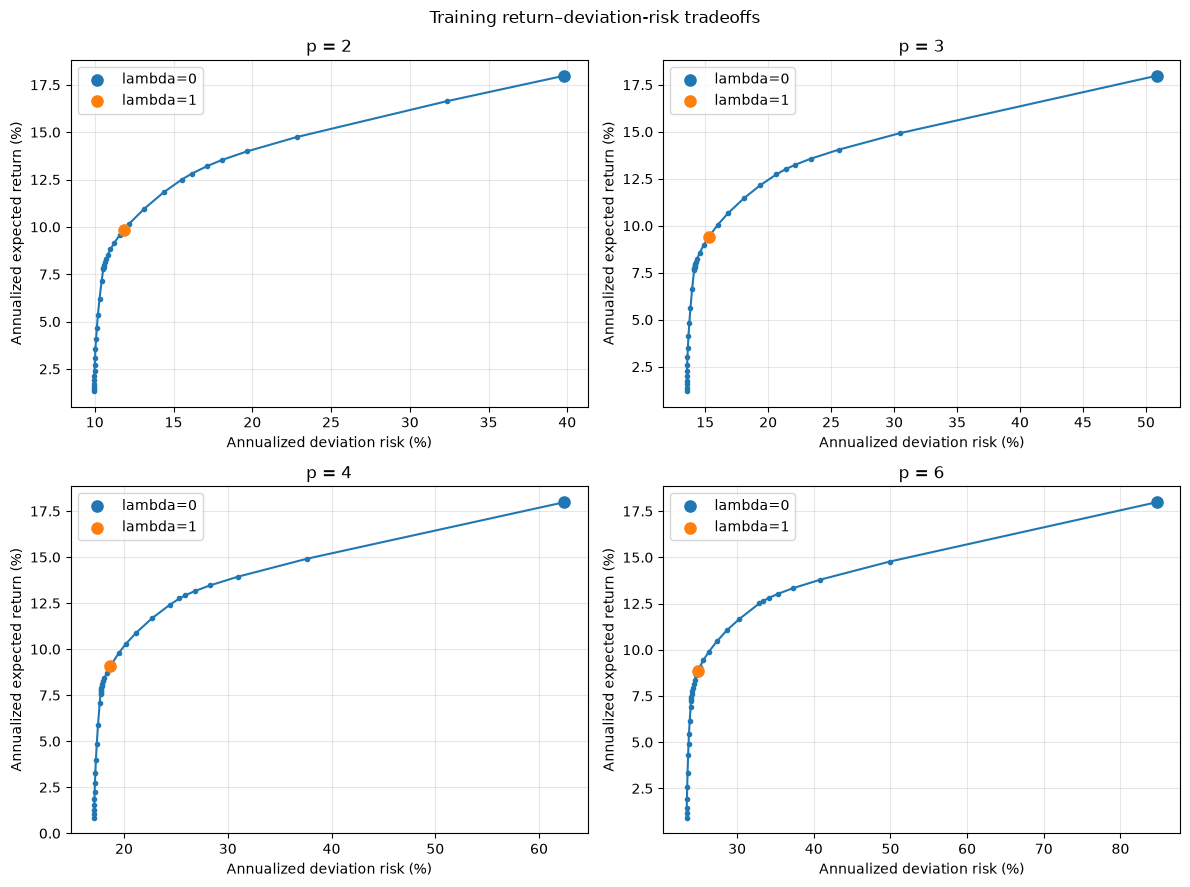

In [112]:

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
# creates a figure with four subplots arranged in a 2x2 grid

for ax, p in zip(axes.flat, P_VALUES):
    # loops through each subplot and assigns one value of p to it

    curve = candidates.loc[candidates['p'] == p].sort_values('deviation_risk')
    # selects all portfolios for the current p and sorts them by deviation risk

    ax.plot(100 * curve['deviation_risk'], 100 * curve['train_return'], 'o-', linewidth=1.5, markersize=3)
    # plots annualized deviation risk against expected return as percentages
    # connects the portfolio results to show the risk-return tradeoff

    for label, value in [('lambda=0', 0.0), ('lambda=1', 1.0)]:
        # loops through two specific lambda values to highlight them

        point = candidates.loc[(candidates['p'] == p) & np.isclose(candidates['lambda'], value)].iloc[0]
        # finds the portfolio corresponding to the current p and lambda value

        ax.scatter(100 * point['deviation_risk'], 100 * point['train_return'], s=65, zorder=3, label=label)
        # highlights the selected portfolio with a larger marker
        # zorder makes sure the marker appears above the plotted curve

    ax.set_title(f'p = {p}')
    # labels the subplot with its corresponding p value

    ax.set_xlabel('Annualized deviation risk (%)')
    # labels the horizontal axis as annualized deviation risk

    ax.set_ylabel('Annualized expected return (%)')
    # labels the vertical axis as annualized expected return

    ax.grid(alpha=0.3)
    # adds a light grid to make the graph easier to read

    ax.legend()
    # displays the legend identifying the two highlighted lambda values

plt.suptitle('Training return–deviation-risk tradeoffs')
# adds an overall title above all four subplots

plt.tight_layout()
# adjusts the spacing so the subplots and labels do not overlap

plt.show()
# displays the completed figure


### Part 2: Interpretation

The four graphs show the relationship between annualized expected return and deviation risk for $p=2,3,4,6$. Each point represents an optimized portfolio at a different $\lambda$, which controls the penalty on risk.

Across all four graphs, increasing $\lambda$ reduces both expected return and deviation risk. At $\lambda=0$, all models select the 100% TSLA portfolio, which has the highest training mean return (approximately 18%). At $\lambda=1$, expected returns decrease to approximately 9–10%, with substantially lower deviation risks.

All four curves show that risk reduction becomes increasingly costly in terms of expected return. Near the minimum-risk end, the curves become almost vertical: further increases in $\lambda$ produce small reductions in risk but larger declines in return. This is consistent with the frontier's slope equaling $\lambda$ wherever differentiable.

The $\lambda$ grids were selected using training data to capture meaningful changes in portfolio allocations. Small $\lambda$ values favor maximum return, while large values approach the minimum-risk portfolio.

Although the curves have similar shapes, their deviation-risk values are not directly comparable across different $p$. Higher $p$ values place greater weight on extreme deviations, changing which portfolios the optimization prefers.

Overall, $\lambda$ determines the risk-return tradeoff, while $p$ determines how deviations are penalized and influences the resulting portfolio allocations.

### Part 3

,Annualized return,p-deviation risk,Covariance volatility,Nonzero assets (> 0.1%),Largest holdings
p,,,,,
2,9.85%,11.85%,11.86%,6,"WMT 45.0%, PG 18.5%, JNJ 15.9%"
3,9.41%,15.29%,11.53%,6,"WMT 45.3%, PG 24.9%, JNJ 16.7%"
4,9.06%,18.68%,11.42%,5,"WMT 46.4%, PG 28.5%, JNJ 17.9%"
6,8.87%,24.90%,11.62%,3,"WMT 49.1%, PG 33.8%, JNJ 17.1%"


,GOOG,TSLA,AAPL,GS,A,AAP,MSFT,AMZN,NVDA,JPM,XOM,JNJ,PG,WMT,CAT,BA
p,,,,,,,,,,,,,,,,
2,0.00%,7.30%,6.24%,0.00%,0.00%,0.00%,0.00%,0.00%,0.00%,0.00%,0.00%,15.87%,18.52%,44.95%,0.00%,7.12%
3,0.00%,4.86%,5.65%,0.00%,0.00%,0.00%,0.00%,0.00%,0.00%,0.00%,0.00%,16.72%,24.92%,45.35%,0.00%,2.50%
4,0.00%,2.24%,4.92%,0.00%,0.00%,0.00%,0.00%,0.00%,0.00%,0.00%,0.00%,17.88%,28.55%,46.41%,0.00%,0.00%
6,0.00%,0.00%,0.00%,0.00%,0.00%,0.00%,0.00%,0.00%,0.00%,0.00%,0.00%,17.10%,33.85%,49.06%,0.00%,0.00%


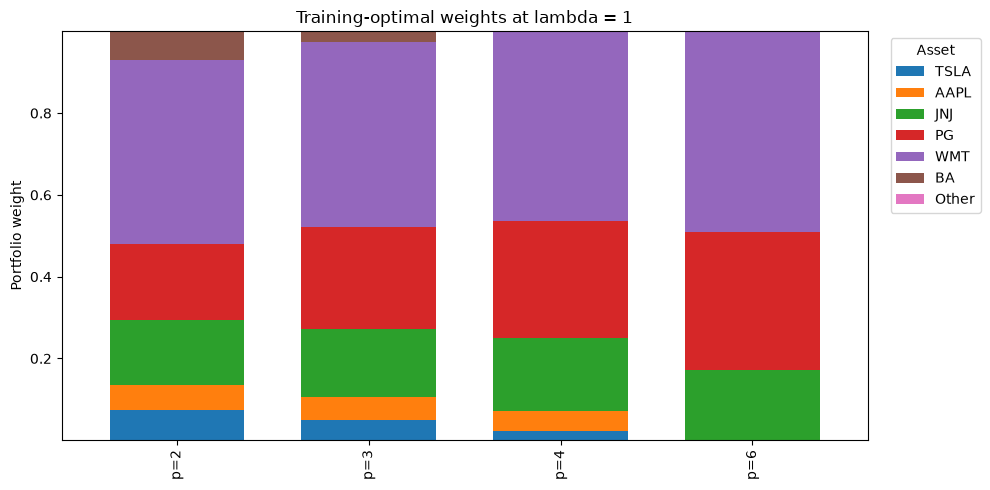

In [113]:

benchmark = candidates.loc[np.isclose(candidates['lambda'], 1.0)].copy()
# selects all candidate portfolios with lambda approximately equal to 1 and creates a copy
benchmark = benchmark.set_index('p').loc[list(P_VALUES)]
# sets p as the index and arranges the portfolios in the specified order of p values
weights_at_one = benchmark[[f'w_{a}' for a in asset_lst]].copy()
# extracts the portfolio weights for each asset at lambda equal to 1
weights_at_one.columns = asset_lst
# renames the weight columns to their corresponding asset tickers
summary_rows = []
# initializes an empty list to store the portfolio comparison results

for p, row in benchmark.iterrows():
    # loops through each p value and its corresponding portfolio data
    ws = weights_at_one.loc[p].sort_values(ascending=False)
    # retrieves the portfolio weights for the current p and sorts them from largest to smallest
    top_three = ', '.join(f'{asset} {weight:.1%}' for asset, weight in ws.head(3).items())
    # identifies the three largest holdings and formats their weights as percentages
    summary_rows.append({
        # adds a dictionary containing the current portfolio's summary statistics
        'p': p,
        # stores the current p value
        'Annualized return': row['train_return'],
        # stores the expected annualized return calculated from the training data
        'p-deviation risk': row['deviation_risk'],
        # stores the annualized deviation risk corresponding to the current p value
        'Covariance volatility': row['annual_volatility'],
        # stores the annualized volatility calculated using the training covariance matrix
        'Nonzero assets (> 0.1%)': int((ws > 1e-3).sum()),
        # counts the number of assets with portfolio weights greater than 0.1 percent
        'Largest holdings': top_three,
        # stores the three assets with the highest portfolio weights
    })
    # completes the dictionary and adds it to the summary list

summary = pd.DataFrame(summary_rows).set_index('p')
# converts the summary list into a dataframe and uses p as the index
display(summary.style.format({
    # displays the summary table with percentage formatting for the selected columns
    'Annualized return': '{:.2%}',
    # formats the annualized expected return as a percentage with two decimal places
    'p-deviation risk': '{:.2%}',
    # formats the annualized deviation risk as a percentage with two decimal places
    'Covariance volatility': '{:.2%}',
    # formats the annualized covariance volatility as a percentage with two decimal places
}))
# completes the formatting instructions and displays the summary table

display(weights_at_one.style.format('{:.2%}'))
# displays the portfolio weights for all 16 assets as percentages with two decimal places

major_assets = weights_at_one.columns[(weights_at_one.max(axis=0) >= 0.01)]
# identifies assets that have at least a 1 percent weight in any of the four portfolios

plot_weights = weights_at_one[major_assets].copy()
# creates a dataframe containing only the selected major assets

plot_weights['Other'] = weights_at_one.drop(columns=major_assets).sum(axis=1)
# combines the weights of all remaining smaller holdings into an other category

plot_weights.index = [f'p={p}' for p in plot_weights.index]
# renames the index labels to show the corresponding p values

ax = plot_weights.plot.bar(stacked=True, figsize=(10, 5), width=0.7)
# creates a stacked bar chart showing the portfolio allocation for each p value

ax.set_title('Training-optimal weights at lambda = 1')
# sets the chart title to describe the optimized portfolios being compared

ax.set_ylabel('Portfolio weight')
# labels the vertical axis as portfolio weight

ax.set_xlabel('')
# removes the horizontal axis label since the p values are already shown

ax.legend(title='Asset', bbox_to_anchor=(1.02, 1), loc='upper left')
# adds a legend identifying each asset and positions it outside the chart on the right

plt.tight_layout()
# adjusts the chart spacing to prevent the labels and legend from overlapping

plt.show()
# displays the completed stacked bar chart


In [114]:
# compare the four p values at the SAME expected return instead of the same lambda.
# at a fixed lambda = 1 the penalty has a different effective strength for each p (the deviation-risk
# scales differ), so differences in return/volatility mix the effect of p with the effect of penalty size
# here, for each p, we minimize the p-deviation risk subject to a common minimum annualized return
target_return = 0.09
# common annualized return target (9%), feasible for all p because the lambda=0 portfolios earn about 18%
matched_rows = []
# creates an empty list to store the matched-return results
for p in P_VALUES:
    # repeats the optimization for each p value
    w_m = cp.Variable(n_assets, nonneg=True)
    # nonnegative portfolio weights (no short selling)
    dev_m = (np.sqrt(ANNUALIZATION) / N ** (1 / p)) * cp.pnorm(D @ w_m, p=p)
    # annualized p-norm deviation risk, same definition as in Part 1
    prob_m = cp.Problem(cp.Minimize(dev_m), [cp.sum(w_m) == 1, mu @ w_m >= target_return])
    # minimizes deviation risk subject to full investment and the minimum return target
    prob_m.solve(solver='CLARABEL')
    # solves the problem with CLARABEL
    assert prob_m.status == cp.OPTIMAL
    # makes sure the solver found an optimal solution
    x_m = np.maximum(np.asarray(w_m.value).ravel(), 0.0)
    # removes tiny negative numerical errors
    x_m /= x_m.sum()
    # renormalizes the weights so they sum to exactly one
    ws_m = pd.Series(x_m, index=asset_lst).sort_values(ascending=False)
    # sorts the weights from largest to smallest
    matched_rows.append({
        'p': p,
        'Annualized return': float(mu @ x_m),
        'p-deviation risk': float(np.sqrt(ANNUALIZATION) *
                                  np.mean(np.abs(D @ x_m) ** p) ** (1 / p)),
        'Covariance volatility': float(np.sqrt(x_m @ Q @ x_m)),
        'Nonzero assets (> 0.1%)': int((ws_m > 1e-3).sum()),
        'Largest holdings': ', '.join(f'{a} {v:.1%}' for a, v in ws_m.head(3).items()),
    })
    # stores return, deviation risk, covariance volatility, number of holdings and top three holdings

matched = pd.DataFrame(matched_rows).set_index('p')
# converts the results into a dataframe indexed by p
display(matched.style.format({
    'Annualized return': '{:.2%}',
    'p-deviation risk': '{:.2%}',
    'Covariance volatility': '{:.2%}',
}))
# display the matched-return comparison table

,Annualized return,p-deviation risk,Covariance volatility,Nonzero assets (> 0.1%),Largest holdings
p,,,,,
2,9.00%,11.12%,11.13%,7,"WMT 36.3%, PG 26.4%, JNJ 17.2%"
3,9.00%,14.91%,11.21%,6,"WMT 41.4%, PG 28.3%, JNJ 17.1%"
4,9.00%,18.62%,11.37%,5,"WMT 45.8%, PG 29.0%, JNJ 17.9%"
6,9.00%,25.04%,11.73%,3,"WMT 51.4%, PG 30.8%, JNJ 17.8%"


### Part 3: Portfolio Comparison and Discussion

I compared the optimized portfolios for $p=2,3,4,6$ at $\lambda=1$, examining their annualized expected returns, deviation risks, covariance volatilities, and asset allocations. Since deviation-risk scales differ across $p$, I also compared portfolios at a common 9% annualized expected return to isolate the effect of $p$.

#### Summary of Results

At $\lambda=1$, increasing $p$ from 2 to 6 decreases annualized expected return from 9.85% to 8.87%, while reported deviation risk increases from 11.85% to 24.90%. However, deviation-risk values are not directly comparable across $p$ because higher values place greater weight on extreme deviations.

Annualized covariance volatility decreases from 11.86% ($p=2$) to 11.42% ($p=4$), before increasing to 11.62% ($p=6$). This non-monotonic pattern partly reflects differences in expected return, since the portfolios are not being compared at a fixed return.

#### Portfolio Allocation and Interpretation

At $p=2$, the portfolio contains six assets with weights above 0.1%, primarily WMT (44.95%), PG (18.52%), and JNJ (15.87%), with smaller allocations to TSLA, AAPL, and BA.

As $p$ increases, weights shift toward WMT and PG, while TSLA, AAPL, and BA receive smaller allocations. At $p=6$, only three assets remain above 0.1%: WMT (49.06%), PG (33.85%), and JNJ (17.10%).

Thus, higher $p$ values produce more concentrated portfolios, suggesting that WMT, PG, and JNJ were relatively effective at limiting larger deviations in the training sample.

#### Matched-Return Comparison (9% Annualized Return)

At a common 9% expected return, the number of holdings above 0.1% decreases from 7 to 6 to 5 to 3 as $p$ increases. WMT's allocation also increases from 36.3% to 51.4%, confirming that higher $p$ values favor greater concentration even when expected return is held constant.

Covariance volatility increases monotonically from 11.13% ($p=2$) to 11.21% ($p=3$), 11.37% ($p=4$), and 11.73% ($p=6$).

The $p=2$ portfolio has the lowest volatility because its deviation-risk measure is proportional to covariance standard deviation. With $N=502$ training observations,

$$
\widetilde{\rho}_2(x)=\sqrt{\frac{501}{502}}\sqrt{x^\top Qx}
$$

Therefore, minimizing $p=2$ deviation risk at a fixed return is equivalent to minimizing covariance volatility. Higher $p$ values prioritize larger deviations instead, potentially producing higher standard deviation.

#### Overall Takeaways

Increasing $p$ produces more concentrated portfolios, particularly in WMT, PG, and JNJ. At $\lambda=1$, expected returns decrease, but the effective risk penalties also differ across $p$.

At a common 9% expected return, covariance volatility increases with $p$, confirming that minimizing higher-order deviation risk does not necessarily minimize standard deviation.

These findings are specific to the 2017–2018 training sample. Validation and test results are needed to assess out-of-sample performance, and deviation-risk values should not be directly compared across different $p$ values.

# Task 2: Static mean--variance and PCA factor models

## Task 2(a): Full-covariance mean--variance optimization

Using annualized training estimates $\mu$ and $Q$, solve

$$
\min_x\quad \lambda x^\top Qx-\mu^\top x
\quad\text{s.t.}\quad x\ge0,\ \mathbf1^\top x=1.
$$

### Requirements

1. Use at least **50 values of $\lambda$**, chosen using training data, and store the resulting portfolios as candidates for Task 3.
2. Plot the annualized expected return $\mu^\top x$ against volatility $\sqrt{x^\top Qx}$.


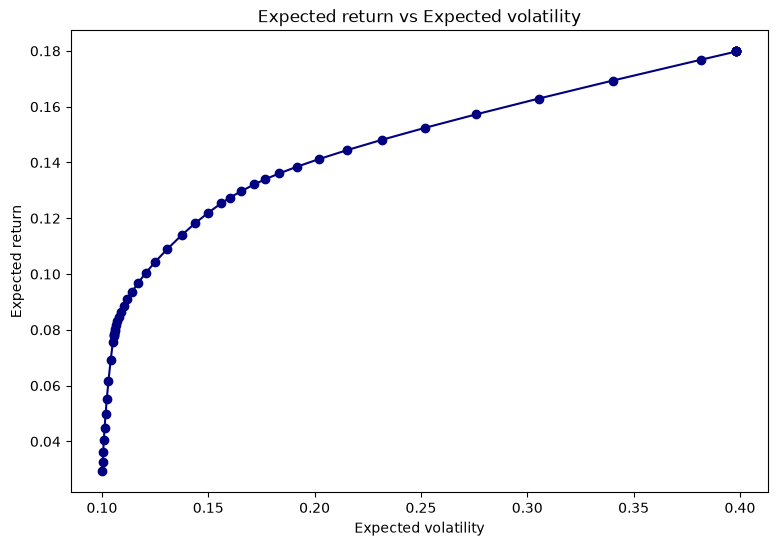

,lambda values,GOOG,TSLA,AAPL,GS,A,AAP,MSFT,AMZN,NVDA,JPM,XOM,JNJ,PG,WMT,CAT,BA
0,1.00e-01,0.00e+00,1.00e+00,9.22e-24,9.74e-24,9.53e-24,9.95e-24,0.00e+00,9.11e-24,8.45e-24,0.00e+00,9.71e-24,0.00e+00,9.53e-24,0.00e+00,1.21e-22,0.00e+00
1,1.15e-01,2.83e-23,1.00e+00,0.00e+00,2.22e-22,1.97e-25,0.00e+00,5.16e-25,8.81e-25,2.24e-22,1.42e-25,1.11e-22,2.74e-23,1.10e-22,0.00e+00,0.00e+00,5.26e-25
2,1.33e-01,0.00e+00,1.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00e+00,5.24e-25,0.00e+00,0.00e+00,1.39e-25,0.00e+00,0.00e+00,0.00e+00,0.00e+00,6.72e-25,0.00e+00
3,1.53e-01,0.00e+00,1.00e+00,0.00e+00,1.81e-22,6.99e-23,0.00e+00,0.00e+00,6.90e-23,1.79e-22,0.00e+00,0.00e+00,0.00e+00,1.48e-23,2.88e-23,0.00e+00,0.00e+00
4,1.76e-01,2.82e-23,1.00e+00,2.80e-23,3.25e-25,1.52e-25,0.00e+00,0.00e+00,2.23e-22,0.00e+00,9.69e-26,0.00e+00,0.00e+00,0.00e+00,0.00e+00,1.12e-22,0.00e+00
5,2.02e-01,0.00e+00,1.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00e+00,6.14e-25,0.00e+00,4.63e-26,0.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00e+00,0.00e+00
6,2.33e-01,0.00e+00,9.55e-01,0.00e+00,0.00e+00,2.34e-23,0.00e+00,0.00e+00,0.00e+00,0.00e+00,2.06e-23,0.00e+00,0.00e+00,0.00e+00,4.52e-02,0.00e+00,0.00e+00
7,2.68e-01,4.89e-23,8.40e-01,2.19e-23,2.74e-22,5.16e-23,1.66e-22,1.05e-22,0.00e+00,2.63e-22,5.26e-23,1.65e-22,2.71e-23,2.64e-23,1.60e-01,5.09e-23,0.00e+00
8,3.09e-01,5.15e-23,7.41e-01,2.67e-23,9.00e-23,8.77e-23,2.10e-22,1.37e-22,7.41e-23,0.00e+00,2.02e-22,9.66e-23,8.57e-23,7.05e-23,2.59e-01,0.00e+00,1.14e-22
9,3.56e-01,1.09e-23,6.54e-01,6.63e-23,0.00e+00,1.22e-22,9.85e-24,0.00e+00,0.00e+00,8.73e-24,1.07e-23,1.08e-23,0.00e+00,0.00e+00,3.46e-01,0.00e+00,8.68e-23


In [115]:
# Task 2(a): your full-covariance mean--variance implementation
from matplotlib.pyplot import subplots
# Function for convex optimization
def solve_opt(lam,df_train,mu,Q):
    # Define variables for cvxpy
    n=df_train.shape[1]
    x=cp.Variable(n)
    # Setting up objective function
    objective=cp.Minimize(lam*cp.quad_form(x,Q)-mu@x)
    # Setting up constraints 
    constraints=[x>=0,cp.sum(x)==1]
    # Solving the optimization
    prob=cp.Problem(objective, constraints)
    prob.solve()
    if prob.status=='optimal':
        # Cliping the negative values
        x=x.value
        x = np.clip(x, 0, None) 
        x = x / x.sum()
        # Return the resulting portfolio X
        return x
    else:
        print('no optimal solution')
        return np.zeros(n)
    
# Function for looping across multiple lambda values
def loop_lambda(df_train,mu,Q):
    # Define a list of 50 lambda values,from 10^(-2) to 10^(2) to cover a reasonable range of lambda, equal step under logspace, to allocate enough points for the sensitve range 
    lambda_vals=np.logspace(-1,2,50)
    # Define a list for the resulting X for each lambda
    x_results=[]
    # call solve_opt, store result
    for idx,lam in enumerate(lambda_vals):
        result=solve_opt(lam,df_train,mu,Q)
        x_results.append(result)
    # Consolidate array of results and corresponding lambda values in to a dataframe, return the df
    df_results=pd.DataFrame({'lambda values':lambda_vals,'optimal allocation':x_results})
    return df_results,x_results
    
# Function for plotting the annualized return against volatility
def plot_return_vol(df_results,x_results,mu,Q):
    # Compute the return and volatility for each x
    df_results['portfolio_return']=x_results@mu #50xn@nx1
    df_results['portfolio_volatility']=np.sqrt(np.diag(x_results@Q@np.array(x_results).T)) #50xn@nxn@nx50
    # plot 
    ax=subplots(figsize=(9,6))[1]
    ax.plot(df_results['portfolio_volatility'], df_results['portfolio_return'],marker='o', color='navy')
    ax.set_title('Expected return vs Expected volatility')
    ax.set_xlabel('Expected volatility')
    ax.set_ylabel('Expected return')
    plt.show()
    return df_results
    
# A function of displaying the optimal allocation across assets
def display_allocation(df_train,df_results):
    # extract 15 assets names
    cols=df_train.columns
    # convert original array of list for asset allocation into matrix (50x15)
    weights=df_results['optimal allocation'].tolist()
    df_allocation=pd.DataFrame(weights,columns=cols)
    # insert a lambda value column at position 0
    df_allocation.insert(0,'lambda values',df_results['lambda values'])
    return df_allocation
                            


# Main function
# Compute mu and Q
df_train=train_returns.copy()
r_mean=df_train.mean()
sigma=df_train.cov()
mu=ANNUALIZATION*r_mean
Q=ANNUALIZATION*sigma
# Converting mu and Q from pd to np array
mu=np.array(mu).flatten()
Q=np.array(Q)
df_results,x_results=loop_lambda(df_train,mu,Q)
# The full results df with return and vol
df_results=plot_return_vol(df_results,x_results,mu,Q)
# A better organized df of results (with lambda value, all 16 assets weight as columns)
df_allocation=display_allocation(df_train,df_results)
# Formatting the table for display
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
df_allocation.style.format("{:.2e}").background_gradient(cmap='Blues',axis=1, subset=df_allocation.columns[1:]).set_properties(**{'white-space': 'nowrap', 'font-size': '10px'})

## Discussion:
1. The algorithm selected equal logspaced value for $\lambda$ to recover the full shape of the efficient frontier, so that it could take more concentrated values in the range where results are sensitive to $\lambda$ changes. The two terms of portfolio volatility and expected return, has the scale in $10^{-2}$ and $10^{-1}$ respectively, so the corresponding range for $\lambda$ could be $10^{-1}$ to $10^{2}$, so that when $\lambda$ is close to the lower bound, the volatility penalty term is negligible, the optimizer focus of maximizing return, locating on the upper right corner of the eifficient frontier, when $\lambda$ is close to upper bound, the two terms have similar magnitude, the points moves towards the minimum variance portfolio. Optimal portfolio weightings are listed above, some solver rounding error of negative values are cliped, with the remaining weights normalized, no sparsity regulation is enforced on the small positive values to show differences between portfolios when $\lambda$ is in the range where results are not sensitive to its changes.

## Output from this section:
- **df_results**: A dataframe with the full result from optimization (but weightings are stored as list in every cell in the column 'optimal allocation'),including the return and volatility,across 50 $\lambda$ values.
- **df_allocation**: A dataframe with weighting of each asset in a seperate column, across 50 $\lambda$ values

## Task 2(b): Static PCA factor model

Apply **covariance PCA** to the training returns (without standardizing individual assets). Use the annualized covariance decomposition

$$
Q=W\Lambda W^\top,\qquad
\Lambda_K=\operatorname{diag}(\ell_1,\ldots,\ell_K),\qquad
W_K=(w^{(1)},\ldots,w^{(K)}).
$$

Construct the PCA factor covariance model

$$
D_K=\operatorname{diag}(Q-W_K\Lambda_KW_K^\top),
\qquad
Q_{\mathrm{PCA},K}=W_K\Lambda_KW_K^\top+D_K.
$$

Introducing $y=W_K^\top x$, solve

$$
\min_{x,y}\quad
\lambda\left(y^\top\Lambda_K y+x^\top D_Kx\right)-\mu^\top x
$$

subject to

$$
x\ge0,\qquad \mathbf1^\top x=1,\qquad y=W_K^\top x.
$$

### Requirements

1. Plot individual and cumulative explained-variance ratios. Let $K_{80}$ be the smallest $K$ explaining at least 80% of the training variance.
2. Use at least **three** choices of $K$, including $K_{80}$. For each, report the relative covariance error $\|Q-Q_{\mathrm{PCA},K}\|_F/\|Q\|_F$.
3. For each selected $K$, solve for at least **50 values of $\lambda$**, and retain the portfolios for Task 3.
4. Compare the training portfolio risk--return tradeoffs under the **same full covariance $Q$**. Discuss how $K$ affects the approximation and the optimal portfolios.
5. For one $K$ and $\lambda$, verify the factor formulation against directly optimizing with $Q_{\mathrm{PCA},K}$.


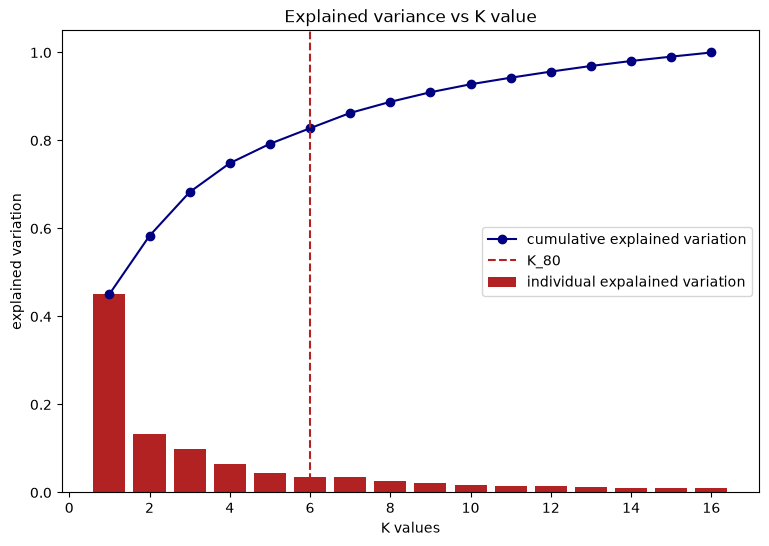

In [116]:
# Task 2(b): your static PCA factor-model implementation
# Function for PCA through Eigenvector decomposition
def PCA(Q):
    # Solve for eigenvector and eigenvalues
    eigenvalues,eigenvectors=np.linalg.eigh(Q)
    # Sort the results,idx as the descending index of eigenvalues matrix,sort eigenvalues and eigenvectors base on the idx
    idx=np.argsort(eigenvalues)[::-1]
    eigenvalues=eigenvalues[idx]
    eigenvectors=eigenvectors[:,idx]
    # Assign variable names to be in line with the problem setting
    cap_lam=np.diag(eigenvalues)
    W=eigenvectors
    # Find K80
    cumsum=np.cumsum(eigenvalues)
    sum_val=np.sum(eigenvalues)
    explained_var=cumsum/sum_val
    K_80=np.argmax(explained_var>=0.8)+1
    df_explained_var=pd.DataFrame({'K value':np.arange(1,len(eigenvalues)+1),'explained variation':explained_var})
    # Return K80,eigenvector and eigenvalues
    return K_80, cap_lam, W,df_explained_var
    
# Function for constructing Qpca for a given K value
def construct_Q_PCA(K,Q,cap_lam,W):
    # For a given value of K, reconstruct D_K and Q_PCA,K
    eigenvalues=np.diag(cap_lam)
    lam_K=np.diag(eigenvalues[:K]) # KxK
    W_K=W[:,:K] #nxK
    D_K=np.diag(np.diag(Q-W_K@lam_K@W_K.T)) # nxn
    Q_PCA=W_K@lam_K@W_K.T+D_K # nxn
    # Compute the relative covariance error
    rel_cov_error=np.linalg.norm(Q - Q_PCA, 'fro') / np.linalg.norm(Q, 'fro')
    # return a dictionary of results
    dict_result={
        'Q_PCA':Q_PCA,
        'W_K':W_K,
        'lam_K':lam_K,
        'D_K':D_K,
        'rel_cov_err':rel_cov_error}
    return dict_result
    
def opt_pca(K,lam,Q_PCA,W_K,lam_K,D_K,df_train,mu): # For values of lambda&K
    # Define variable x and y
    n=df_train.shape[1]
    x=cp.Variable(n)
    y=cp.Variable(K)
    # Define objective function
    objective=cp.Minimize(lam*(cp.quad_form(y,lam_K)+cp.quad_form(x,D_K))-mu@x)
    # Define constraints
    constraints=[ x>=0, cp.sum(x)==1, y==W_K.T@x]
    # Solve the problem, return x,y
    prob=cp.Problem(objective, constraints)
    prob.solve()
    if prob.status=='optimal':
        # Clip negative x values and normalize, recompute y accordingly
        x=x.value
        x=np.clip(x,0,None)
        x=x/np.sum(x)
        y=W_K.T@x
        # Return the resulting portfolio X
        return x,y
    else:
        print('no optimal solution')
        return np.zeros(n),np.zeros(K)

def direct_opt(K,lam,Q_PCA,df_train,mu): # optimization with Q_PCA without defining y)
    # Define variable x and y
    n=df_train.shape[1]
    x=cp.Variable(n)
    # Define objective function
    objective=cp.Minimize(lam*cp.quad_form(x,Q_PCA)-mu@x)
    # Define constraints
    constraints=[ x>=0, cp.sum(x)==1]
    # Solve the problem, return x
    prob=cp.Problem(objective, constraints)
    prob.solve()
    if prob.status=='optimal':
        # Clip negative x values and normalize
        x=x.value
        x=np.clip(x,0,None)
        x=x/np.sum(x)
        # Return the resulting portfolio X
        return x
    else:
        print('no optimal solution')
        return np.zeros(n)

def store_results(Q,mu,df_results,df_train,K_80, cap_lam):
    # Define some K along with K80
    lst_K=[1,K_80,9]
    # Extract lambda values from df_results in 2a)
    lam_values=df_results['lambda values'].values
    # Create a list for the row datas
    rows=[]
    cov_err=[] # a list for rel_cov_error result across K
    # call construct_Q_PCA for each K
    for i,K in enumerate(lst_K):
        dict_result=construct_Q_PCA(K,Q,cap_lam,W)
        rel_cov_error=dict_result['rel_cov_err']
        cov_err.append({
            'K values':K,
            'rel_cov_err':rel_cov_error})
        # Extract variables from the dictionary
        Q_PCA=dict_result['Q_PCA']
        W_K=dict_result['W_K']
        lam_K=dict_result['lam_K']
        D_K=dict_result['D_K']
        for idx,lam in enumerate(lam_values):
            # For each Lambda, Call opt_pca for the results
            x,y=opt_pca(K,lam,Q_PCA,W_K,lam_K,D_K,df_train,mu) #nx1,Kx1
            # Also do a direct OPT on Q_PCA without defining y
            x_direct=direct_opt(K,lam,Q_PCA,df_train,mu)
            portfolio_return=mu.T@x
            portfolio_vol=np.sqrt(x.T@Q@x)
            direct_return=mu.T@x_direct
            direct_vol=np.sqrt(x_direct.T@Q@x_direct)
            # Store the results in a dictionary
            row_data={
            'K value':K,
            'lambda values':lam,
            'Relative covariance error:':rel_cov_error,
            'optimal allocation':x.tolist(),
            'PC score':y.tolist(),
            'portfolio_return':portfolio_return,
            'portfolio_volatility':portfolio_vol,
            'Allocation from direct OPT':x_direct.tolist(),
            'return(direct)':direct_return,
            'volatility(direct)':direct_vol}
            rows.append(row_data)
    df_results_PCA=pd.DataFrame(rows)
    df_cov_err=pd.DataFrame(cov_err)
    return df_results_PCA,df_cov_err

# Function of plot
def plot_explained_var(df_explained_var,K_80):
    # Process the cumulative explained variation df for the individual explained variance
    individual_var=df_explained_var['explained variation'].diff()
    individual_var[0]=df_explained_var['explained variation'][0]
    ax=subplots(figsize=(9,6))[1]
    ax.plot(df_explained_var['K value'], df_explained_var['explained variation'],marker='o', color='navy',label='cumulative explained variation')
    ax.bar(df_explained_var['K value'],individual_var,color='firebrick',label='individual expalained variation')
    ax.axvline(x=K_80,color='firebrick',linestyle='--',label='K_80')
    ax.set_title('Explained variance vs K value')
    ax.set_xlabel('K values')
    ax.set_ylabel('explained variation')
    plt.legend()
    plt.show()
    return 
    
# Function of comparing risk return trade off across different K
def evaluation(df_results_PCA,df_results):
    # plot efficient frontier of 3 K values, and one from a) with full Q optimized results
    ax=subplots(figsize=(9,6))[1]
    lst_K=df_results_PCA['K value'].unique()
    ax.plot(df_results['portfolio_volatility'], df_results['portfolio_return'],color='navy',label='full Q result')
    COLOR=['firebrick','steelblue','rebeccapurple']
    for idx,K in enumerate(lst_K):
        mask=df_results_PCA['K value']==K
        ax.plot(df_results_PCA[mask]['portfolio_volatility'], df_results_PCA[mask]['portfolio_return'],color=COLOR[idx],label=f'K value {K}')
    ax.set_title('return and variance trade-off across different K values')
    ax.set_xlabel('Portfolio volatility')
    ax.set_ylabel('Portfolio return')
    plt.legend()
    plt.show()
    # Plot sparsity of allocation across K through inverse HHI
    ax1=subplots(figsize=(9,6))[1]
    lambdas=df_results_PCA['lambda values'][:50]
    # 2a)'s result 
    effective_asset=[]
    for w in df_results['optimal allocation']:
        w=np.array(w)
        eff=1/np.sum(w**2) if np.sum(w**2) >0 else 0
        effective_asset.append(eff)
    ax1.plot(lambdas,effective_asset,marker='o',color='navy',label='full Q result')
    for idx,K in enumerate(lst_K):
         mask=df_results_PCA['K value']==K
         effective_asset=[]
         for w in df_results_PCA[mask]['optimal allocation']:
             w=np.array(w)
             eff=1/np.sum(w**2) if np.sum(w**2) >0 else 0
             effective_asset.append(eff)
         ax1.plot(lambdas,effective_asset,marker='o',color=COLOR[idx],label=f'K value {K}')
    ax1.set_xscale('log')
    ax1.set_xlabel('lambda values')
    ax1.set_ylabel('effective number of assets')
    plt.legend()
    plt.show()
    return

# Displaying the optimal portfolios
def display_table(df_train,df,col_name):
    # Resetting index of df for later K values
    df=df.reset_index(drop=True)
    # extract 15 assets names
    cols=df_train.columns
    # convert original array of list for asset allocation into matrix (50x15)
    weights=df[col_name].tolist()
    df_allocation_PCA=pd.DataFrame(weights,columns=cols)
    # insert a lambda value column at position 0
    df_allocation_PCA.insert(0,'lambda values',df['lambda values'])
    return df_allocation_PCA
    
# Main function 
# Run PCA
K_80, cap_lam, W,df_explained_var=PCA(Q)
# plot
plot_explained_var(df_explained_var,K_80)
# Get the results across lam and K value pairs and store them
df_results_PCA,df_cov_err=store_results(Q,mu,df_results,df_train,K_80, cap_lam)


### Discussion 1:
The cumulative explained variation by the PC's and their individual explained variations are listed above, the 1st PC explained around 45% of variation in the data, with $K_{80}$ being 6

### Discussion 2:
The three values chosen for $K$ are $1,6,9$, with $K_{80}=6$, the relative covariance error are listed as follows, the larger is the $K$ value, the more variation is preserved from original $Q$, si relative covariance error decline.

In [117]:
# Comparison of K's effect through evaluating relative covariance error values and the optimal allocation weights 
# Output the relative covariance error
df_cov_err.style.format("{:.2e}").set_properties(**{'white-space': 'nowrap', 'font-size': '15px'})


,K values,rel_cov_err
0,1.00e+00,1.99e-01
1,6.00e+00,6.65e-02
2,9.00e+00,4.28e-02


### Discussion 3:
Same value in Task 2a) are chose for $\lambda$, portolios are shown below, one table per value of $K$, these are result from  the factor formulated optimization, with also an algorithm to compare the the results of direct optimization from $Q_{PCA,k}$ and allow relative error upto $10^{-5}$ and absolute error up to $10^{-8}$ to allow for rounding errors. All values from the 150 lines are considered the same, output of verification results are printed under title for each of the three tables.

In [118]:
# Displaying the optimal portfolios for each K across 50 lambda values,check the results with direct opt without introducing Y
from IPython.display import display
K_values=df_results_PCA['K value'].unique()
# Create a dictionary to store the df_allocation_PCA for each value of K:
dict_allocation_PCA={}
for K in K_values:
    mask=df_results_PCA['K value']==K
    df_allocation_PCA=display_table(df_train,df_results_PCA[mask],'optimal allocation')
    df_direct=display_table(df_train,df_results_PCA[mask],'Allocation from direct OPT')
    # Store df_allocation_PCA in dictionary
    dict_allocation_PCA[K]=df_allocation_PCA
    print(f'------Optimal allocation with K={K}-----------')
    # Compare the results of two optimization
    if np.allclose(df_allocation_PCA,df_direct,rtol=1e-05,atol=1e-08)==True:
        print(f'------the result is the same with direct optimization without y-----------')
    styled_table = df_allocation_PCA.style.format("{:.2e}")\
        .background_gradient(cmap='Blues',axis=1,subset=df_allocation_PCA.columns[1:])\
        .set_properties(**{'white-space': 'nowrap', 'font-size': '10px'})
    display(styled_table)

------Optimal allocation with K=1-----------
------the result is the same with direct optimization without y-----------


,lambda values,GOOG,TSLA,AAPL,GS,A,AAP,MSFT,AMZN,NVDA,JPM,XOM,JNJ,PG,WMT,CAT,BA
0,1.00e-01,2.23e-23,1.00e+00,7.78e-23,7.78e-23,1.89e-22,7.80e-23,7.78e-23,1.89e-22,7.81e-23,7.78e-23,7.77e-23,4.99e-23,7.77e-23,9.16e-23,0.00e+00,7.78e-23
1,1.15e-01,7.62e-23,1.00e+00,7.76e-23,3.28e-22,1.06e-22,1.09e-22,0.00e+00,0.00e+00,9.70e-23,1.07e-22,2.20e-22,1.10e-22,5.48e-23,8.15e-23,1.04e-22,1.05e-22
2,1.33e-01,6.12e-23,1.00e+00,6.20e-23,3.47e-23,3.48e-23,3.64e-23,3.37e-23,0.00e+00,2.52e-22,1.46e-22,3.64e-23,3.67e-23,6.49e-23,5.05e-23,1.45e-22,3.40e-23
3,1.53e-01,7.17e-23,1.00e+00,4.48e-23,0.00e+00,7.32e-23,7.50e-23,7.20e-23,0.00e+00,2.89e-22,7.37e-23,0.00e+00,1.03e-22,7.59e-23,8.91e-23,1.83e-22,7.22e-23
4,1.76e-01,8.55e-23,1.00e+00,8.78e-23,0.00e+00,1.17e-22,1.21e-22,2.99e-24,1.10e-22,0.00e+00,1.18e-22,2.33e-22,6.71e-23,9.61e-23,8.75e-23,1.14e-22,8.68e-23
5,2.02e-01,4.29e-23,1.00e+00,4.54e-23,7.41e-23,0.00e+00,7.89e-23,7.14e-23,6.75e-23,0.00e+00,1.87e-22,0.00e+00,5.28e-23,5.42e-23,6.97e-23,7.14e-23,5.82e-23
6,2.33e-01,1.02e-22,9.73e-01,5.15e-23,2.75e-22,0.00e+00,1.74e-22,1.04e-22,0.00e+00,2.23e-23,0.00e+00,1.75e-22,6.58e-23,9.61e-23,2.66e-02,1.59e-22,4.94e-23
7,2.68e-01,2.21e-23,8.54e-01,5.57e-23,3.02e-23,3.15e-23,4.17e-23,7.95e-23,1.25e-22,0.00e+00,3.47e-23,4.38e-23,7.35e-23,4.90e-23,1.46e-01,2.38e-23,3.92e-23
8,3.09e-01,0.00e+00,7.51e-01,3.77e-23,1.05e-23,0.00e+00,1.30e-23,0.00e+00,7.71e-24,3.97e-24,1.12e-23,1.24e-22,2.70e-23,0.00e+00,2.49e-01,9.44e-24,9.62e-24
9,3.56e-01,1.90e-23,6.61e-01,1.95e-23,0.00e+00,0.00e+00,1.04e-22,0.00e+00,1.02e-22,0.00e+00,0.00e+00,0.00e+00,6.94e-24,0.00e+00,3.39e-01,1.03e-22,1.94e-23


------Optimal allocation with K=6-----------
------the result is the same with direct optimization without y-----------


,lambda values,GOOG,TSLA,AAPL,GS,A,AAP,MSFT,AMZN,NVDA,JPM,XOM,JNJ,PG,WMT,CAT,BA
0,1.00e-01,0.00e+00,1.00e+00,0.00e+00,4.38e-23,4.38e-23,4.37e-23,0.00e+00,0.00e+00,4.32e-23,0.00e+00,0.00e+00,0.00e+00,4.02e-23,5.69e-23,0.00e+00,1.77e-23
1,1.15e-01,2.65e-23,1.00e+00,1.10e-22,8.45e-23,0.00e+00,8.65e-23,1.94e-22,0.00e+00,0.00e+00,0.00e+00,8.57e-23,8.79e-23,2.92e-23,1.01e-22,8.37e-23,5.76e-23
2,1.33e-01,7.92e-23,1.00e+00,7.79e-23,5.24e-22,1.91e-22,3.02e-22,1.91e-22,1.91e-22,7.93e-23,4.12e-22,7.86e-23,5.27e-23,1.04e-22,1.07e-22,8.09e-23,8.22e-23
3,1.53e-01,1.97e-22,1.00e+00,1.40e-22,0.00e+00,1.97e-22,6.39e-22,1.97e-22,1.99e-22,0.00e+00,1.95e-22,1.93e-22,2.50e-22,1.34e-22,1.59e-22,1.99e-22,2.27e-22
4,1.76e-01,1.83e-22,1.00e+00,1.83e-22,1.84e-22,2.96e-22,4.08e-22,1.84e-22,1.83e-22,6.83e-23,2.95e-22,2.96e-22,2.15e-22,2.12e-22,1.93e-22,4.06e-22,1.86e-22
5,2.02e-01,5.85e-23,1.00e+00,8.71e-23,3.37e-22,1.17e-22,1.18e-22,5.93e-23,1.13e-22,1.08e-22,1.16e-22,3.40e-22,1.21e-22,6.33e-23,1.20e-22,1.14e-22,1.16e-22
6,2.33e-01,5.07e-23,9.55e-01,5.60e-23,0.00e+00,0.00e+00,0.00e+00,0.00e+00,3.54e-23,0.00e+00,0.00e+00,0.00e+00,1.39e-22,1.16e-22,4.49e-02,1.89e-22,6.35e-23
7,2.68e-01,3.90e-23,8.40e-01,1.30e-23,6.04e-23,2.70e-22,4.02e-22,0.00e+00,3.07e-23,0.00e+00,5.90e-23,6.03e-23,5.33e-23,4.42e-25,1.60e-01,1.69e-22,6.01e-23
8,3.09e-01,9.24e-23,7.41e-01,6.43e-23,0.00e+00,9.29e-23,1.05e-22,3.54e-23,2.00e-22,0.00e+00,1.02e-22,9.91e-23,6.18e-23,6.68e-23,2.59e-01,2.16e-22,9.27e-23
9,3.56e-01,1.20e-23,6.54e-01,1.15e-23,4.93e-22,2.63e-22,5.05e-23,3.92e-23,3.76e-23,0.00e+00,2.69e-22,4.47e-23,3.91e-23,4.09e-23,3.46e-01,4.92e-23,3.45e-23


------Optimal allocation with K=9-----------
------the result is the same with direct optimization without y-----------


,lambda values,GOOG,TSLA,AAPL,GS,A,AAP,MSFT,AMZN,NVDA,JPM,XOM,JNJ,PG,WMT,CAT,BA
0,1.00e-01,1.83e-22,1.00e+00,9.96e-23,0.00e+00,2.95e-22,6.30e-22,1.83e-22,0.00e+00,1.80e-22,1.84e-22,2.96e-22,1.31e-22,2.39e-22,1.72e-22,1.84e-22,1.84e-22
1,1.15e-01,1.06e-22,1.00e+00,1.33e-22,1.09e-22,0.00e+00,1.09e-22,1.07e-22,2.17e-22,1.03e-22,0.00e+00,1.08e-22,1.09e-22,5.04e-23,1.37e-22,2.19e-22,1.07e-22
2,1.33e-01,2.37e-22,1.00e+00,2.08e-22,2.10e-22,9.82e-23,2.10e-22,4.31e-22,2.10e-22,2.09e-22,3.20e-22,3.19e-22,1.82e-22,2.06e-22,2.23e-22,0.00e+00,1.82e-22
3,1.53e-01,1.99e-22,1.00e+00,1.15e-22,1.72e-22,1.71e-22,1.70e-22,2.83e-22,2.84e-22,0.00e+00,5.93e-23,5.78e-23,1.42e-22,1.66e-22,1.91e-22,1.73e-22,1.72e-22
4,1.76e-01,6.73e-23,1.00e+00,1.78e-22,3.75e-22,0.00e+00,3.75e-22,4.02e-23,0.00e+00,0.00e+00,2.63e-22,2.63e-22,2.09e-22,1.78e-22,1.54e-22,4.09e-23,1.51e-22
5,2.02e-01,1.57e-22,1.00e+00,1.58e-22,3.84e-22,3.82e-22,1.64e-22,2.14e-22,1.56e-22,0.00e+00,1.61e-22,2.74e-22,1.65e-22,1.61e-22,1.81e-22,4.89e-23,1.87e-22
6,2.33e-01,1.88e-22,9.54e-01,1.48e-22,1.91e-22,4.36e-22,3.20e-22,1.08e-22,3.59e-22,8.18e-23,1.86e-22,1.88e-22,1.92e-22,1.50e-22,4.60e-02,2.87e-22,1.61e-22
7,2.68e-01,1.68e-22,8.40e-01,1.35e-22,3.88e-22,1.80e-22,2.94e-22,1.44e-22,0.00e+00,7.58e-23,2.75e-22,1.69e-22,1.74e-22,1.63e-22,1.60e-01,1.53e-22,1.26e-22
8,3.09e-01,8.65e-23,7.40e-01,0.00e+00,0.00e+00,2.00e-22,2.01e-22,1.72e-22,1.56e-22,0.00e+00,7.54e-23,7.97e-23,8.44e-23,1.97e-23,2.60e-01,0.00e+00,8.22e-23
9,3.56e-01,8.18e-23,6.54e-01,1.72e-23,0.00e+00,2.11e-22,2.00e-22,2.61e-23,4.09e-22,0.00e+00,0.00e+00,1.91e-22,2.50e-23,1.78e-23,3.46e-01,0.00e+00,8.37e-23


## Discussion 4
Plotting the return and variance trade-off across 3 K values and the full covariance matrix optimization result in part a),the lines are of the same shape in the smaller $\lambda$ region(upper right corner),which is intuitive as negligible penalty on portofolio volatiltiy remove any effect of changing covariance vector value.

As K increases in value, $Q_{PCA,k}$ become closer in resemblence of $Q$, the shape of the curve move towards the steel blue line for the full model. Retaining only partial variation of the data through PCA tends to results in larger portfolio volatility in the region with large $\lambda$ values compared to optimization with Q, since the optimal portfolio is obtained through minimizing an objective function with understated variance $Q_{PCA,K}$, removing the covariance terms of loadings beyond K, and here the portfolio volatility is recovered through the actual covariance matrix Q, there will be minor increase compared to part a)'s result, resulting in suboptimal result.

K's effects are also evident through relative covariance error values, already discussed in discussion 2.

Changing K values also has obvious effects on the optimal allocation across assets in the region of large $\lambda$ values. When $K=1$, majority of variation are left out, especially covariation of factors,the resulting allocation is sparse, concentrating on a few assets, since the correlated risk of certain high return assets may be overlooked in the optimization. As K increase, the risk structure across assets becomes more complete, there is more diversification across assets.The marginal effect of same changes in absolute value of K diminished beyond $K_{80}$. 




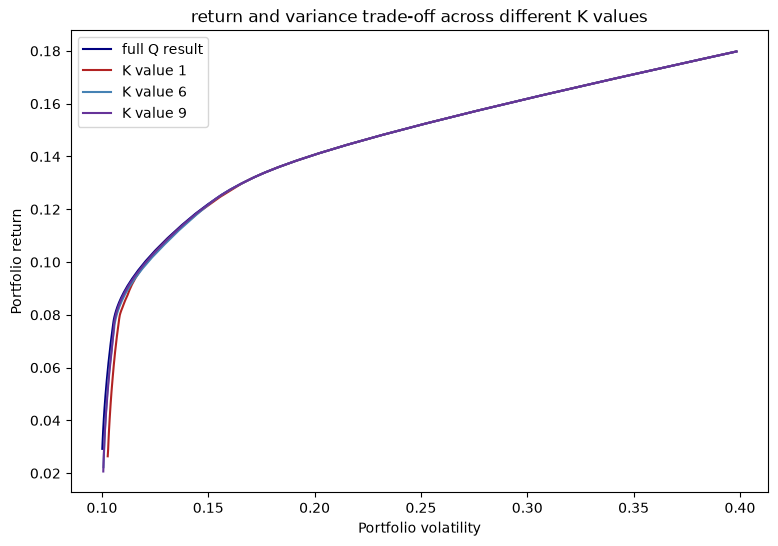

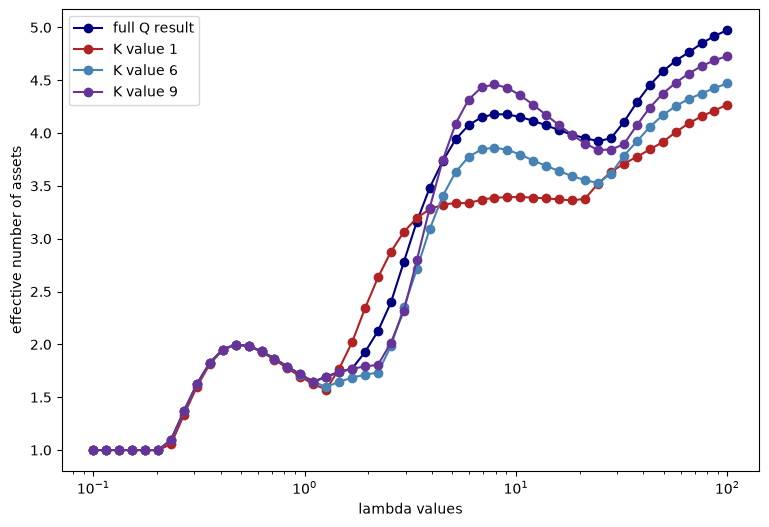

In [119]:
# Plot efficient frontier across K
evaluation(df_results_PCA,df_results)

### Discussion 5:
Taking the specific row with $K=6$ and $\lambda=3.39$, the resulting weighting vector from factor formulation and direct optimization with $Q_{PCA,k}$ are ouput below, it is evident that they are the same up to tolerence of solver rounding error$

In [120]:
# Outputting the result for a specific K and lambda to verify direct OPT and introduction of y generate the same result
print(f'-------------Result from factor formulation at K={df_results_PCA["K value"][75]}, lambda value={df_results_PCA["lambda values"][75]}-------------')
print(f'portfolio weighting are:{df_results_PCA["optimal allocation"][75]}')
print(f'PCA score (y values) are:{df_results_PCA["PC score"][75]}')
print(f'-------------Result from direct optimization with Q_PCA,K at K={df_results_PCA["K value"][75]}, lambda value={df_results_PCA["lambda values"][75]}-------------')
print(f'portfolio weighting are:{df_results_PCA["Allocation from direct OPT"][75]}')


-------------Result from factor formulation at K=6, lambda value=3.393221771895328-------------
portfolio weighting are:[0.011467204038354384, 0.09768292949261839, 0.07276836487012092, 2.2747262710000115e-22, 6.323580511345251e-23, 1.3032664427298387e-22, 1.339740347292653e-23, 0.0, 1.1222511945810226e-22, 0.0, 2.9661633251350623e-25, 0.004436871349748966, 0.17122726197149007, 0.5642204323017793, 0.0, 0.078196935975888]
PCA score (y values) are:[0.14216128967070615, -0.05224856114433357, 0.1192445988620488, -0.04801073006811178, 0.10864205970187385, -0.3512860305104588]
-------------Result from direct optimization with Q_PCA,K at K=6, lambda value=3.393221771895328-------------
portfolio weighting are:[0.011467204038354294, 0.09768292949261838, 0.07276836487012096, 5.169043643649362e-23, 1.0961121478628233e-23, 8.584211765577861e-23, 5.893431610059155e-23, 0.0, 0.0, 1.5501632319889653e-22, 0.0, 0.004436871349748788, 0.17122726197149007, 0.5642204323017794, 0.0, 0.0781969359758881]


## Outputs for this section
- **df_results_PCA**: A dataframe with the full result from optimization under PCA (but weightings are stored as list in every cell in the column 'optimal allocation'),including the return and volatility,across 50 $\lambda$ values paired with 3 values for K.
- **dict_allocation_PCA**: a dictionary with allocations, key values are K values, value of each key is a dataframe with columns as '$\lambda$ values', and 16 assets names.

# Task 3: Validation selection and out-of-sample evaluation

## Task 3(a): Portfolio selection

Using only the **static candidates from Tasks 1--2**, choose the portfolio with the highest total validation-period P&L.

For a candidate $x$, assume that **$V_0=\$10^9$ is invested at the beginning of each day** and all positions are closed at the end of that day:

$$
\operatorname{PnL}_s(x)=V_0\,r_s^\top x,
\qquad
\operatorname{TotalPnL}(x)=\sum_s\operatorname{PnL}_s(x).
$$

The daily notional resets to $V_0$; do not compound daily returns.

### Requirements

1. Report the selected model, parameters, weights, validation total P&L, average daily return, and daily return volatility.
2. Compare the best validation candidate from each of the three model classes.

Do not use validation data to refit models or modify the candidate grids.


In [121]:
# Task 3(a): evaluate all static candidates on the validation period and select the best portfolio

task1_candidates = candidates.copy()

# for all three model classes
candidates = []

#2a) mean-variance portfolios
for _, row in df_results.iterrows():
    candidates.append({
        'model': 'Mean-Variance',
        'lambda': row['lambda values'],
        'weights': np.asarray(row['optimal allocation'], dtype=float)
    })

# 2b) PCA portfolios
for _, row in df_results_PCA.iterrows():
    candidates.append({
        'model': 'PCA',
        'lambda': row['lambda values'],
        'weights': np.asarray(row['optimal allocation'], dtype=float)
    })

#TASK 1: Generalized Deviation portfolios
weight_cols = [f'w_{asset}' for asset in asset_lst]

for _, row in task1_candidates.iterrows():
    candidates.append({
        'model': 'Generalized Deviation',
        'lambda': row['lambda'],
        'weights': row[weight_cols].to_numpy(dtype=float)
    })


candidates_df = pd.DataFrame(candidates)

print("Number of candidates:", len(candidates_df))
display(candidates_df.head())

Number of candidates: 368


,model,lambda,weights
0,Mean-Variance,0.100000,"[0.0, 1.0, 9.22403660670411e-24, 9.73793594503..."
1,Mean-Variance,0.115140,"[2.8309142457135583e-23, 1.0, 0.0, 2.224311108..."
2,Mean-Variance,0.132571,"[0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 5.2359149372040..."
3,Mean-Variance,0.152642,"[0.0, 1.0, 0.0, 1.8120627757356278e-22, 6.9948..."
4,Mean-Variance,0.175751,"[2.824126353233554e-23, 1.0, 2.799253164061461..."


In [122]:

V0 = 1e9

# Calculate total validation P&L for each portfolio
def calculate_pnl(weights, returns):
    daily_returns = returns.to_numpy() @ weights
    daily_pnl = V0 * daily_returns
    return daily_pnl.sum()

# all 368 candidates
candidates_df['validation_pnl'] = candidates_df['weights'].apply(
    lambda w: calculate_pnl(w, validation_returns)
)

display(candidates_df.head())

,model,lambda,weights,validation_pnl
0,Mean-Variance,0.100000,"[0.0, 1.0, 9.22403660670411e-24, 9.73793594503...",2.273272e+07
1,Mean-Variance,0.115140,"[2.8309142457135583e-23, 1.0, 0.0, 2.224311108...",2.273272e+07
2,Mean-Variance,0.132571,"[0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 5.2359149372040...",2.273272e+07
3,Mean-Variance,0.152642,"[0.0, 1.0, 0.0, 1.8120627757356278e-22, 6.9948...",2.273272e+07
4,Mean-Variance,0.175751,"[2.824126353233554e-23, 1.0, 2.799253164061461...",2.273272e+07


In [123]:
# sort from highest to lowest validation P&L
ranked_candidates = candidates_df.sort_values(
    by='validation_pnl',
    ascending=False
)

#best validation candidate from each model
best_per_model = ranked_candidates.drop_duplicates(subset='model')

display(best_per_model.drop(columns=['weights']))

# top 10 portfolios
display(ranked_candidates.head(10))

# Select the best portfolio
best_candidate = ranked_candidates.iloc[0]
best_weights = best_candidate['weights']

# find K value for the selected PCA portfolio
matching_pca = df_results_PCA[
    np.isclose(df_results_PCA['lambda values'], best_candidate['lambda'])
]

for _, row in matching_pca.iterrows():
    if np.allclose(row['optimal allocation'], best_weights, atol=1e-6):
        print("Best K:", row['K value'])
        break

print("Best model:", best_candidate['model'])
print("Best lambda:", best_candidate['lambda'])
print(f"Best validation P&L: ${best_candidate['validation_pnl']:,.2f}")
print("Best portfolio weights:", best_weights)


,model,lambda,validation_pnl
125,PCA,3.393222,1.787007e+08
313,Generalized Deviation,5.608622,1.694675e+08
37,Mean-Variance,18.420700,1.656003e+08


,model,lambda,weights,validation_pnl
125,PCA,3.393222,"[0.011467204038354384, 0.09768292949261839, 0....",1.787007e+08
126,PCA,3.906940,"[0.024193279893687428, 0.08219645063488798, 0....",1.776683e+08
124,PCA,2.947052,"[3.979959114246662e-24, 0.11564266577020932, 0...",1.773451e+08
127,PCA,4.498433,"[0.035246021517266364, 0.06874626760758938, 0....",1.767716e+08
128,PCA,5.179475,"[0.04484545332847982, 0.05706463066934319, 0.1...",1.759928e+08
129,PCA,5.963623,"[0.05318266903806928, 0.04691899612444237, 0.1...",1.753164e+08
130,PCA,6.866488,"[0.060423635707266006, 0.03810739712827138, 0....",1.747289e+08
131,PCA,7.906043,"[0.06671249761641797, 0.030454423179160913, 0....",1.742187e+08
132,PCA,9.102982,"[0.0721744457124681, 0.023807728261335658, 0.1...",1.737756e+08
123,PCA,2.559548,"[1.42335284887495e-23, 0.1357562771602436, 0.0...",1.735633e+08


Best K: 6
Best model: PCA
Best lambda: 3.393221771895328
Best validation P&L: $178,700,700.36
Best portfolio weights: [1.14672040e-02 9.76829295e-02 7.27683649e-02 2.27472627e-22
 6.32358051e-23 1.30326644e-22 1.33974035e-23 0.00000000e+00
 1.12225119e-22 0.00000000e+00 2.96616333e-25 4.43687135e-03
 1.71227262e-01 5.64220432e-01 0.00000000e+00 7.81969360e-02]


In [124]:
# daily returns for best portfolio
best_daily_returns = validation_returns.to_numpy() @ best_weights

#validation statistics
avg_daily_return = np.mean(best_daily_returns)
daily_volatility = np.std(best_daily_returns, ddof=1)

print(f"Average daily return: {avg_daily_return:.4%}")
print(f"Daily volatility: {daily_volatility:.4%}")
print(f"Total validation P&L: ${best_candidate['validation_pnl']:,.2f}")


Average daily return: 0.1441%
Daily volatility: 0.5869%
Total validation P&L: $178,700,700.36


## Task 3(b): Out-of-sample evaluation

Evaluate the portfolio selected in Task 3(a) on the **test period**, without changing its weights or parameters.

### Requirements

1. Report average daily test return, total test P&L, and daily return volatility.
2. Report the same statistics for the equal-weight portfolio $x_i=1/16$.
3. Compare validation and test performance.

Use the same daily-notional convention as Task 3(a). Do not use the test period for model selection.


In [125]:
# Task 3(b): final out-of-sample evaluation

# Daily returns on test period (w selected portfolio)
test_daily_returns = test_returns.to_numpy() @ best_weights

# statistics
test_avg_return = np.mean(test_daily_returns)
test_volatility = np.std(test_daily_returns, ddof=1)
test_total_pnl = V0 * test_daily_returns.sum()

print(f"Test average daily return: {test_avg_return:.4%}")
print(f"Test daily volatility: {test_volatility:.4%}")
print(f"Test total P&L: ${test_total_pnl:,.2f}")


Test average daily return: -0.0147%
Test daily volatility: 0.6439%
Test total P&L: $-18,792,600.59


In [126]:
#equal weight portfolio
equal_weights = np.ones(16) / 16

#daily returns
equal_daily_returns = test_returns.to_numpy() @ equal_weights

equal_avg_return = np.mean(equal_daily_returns)
equal_volatility = np.std(equal_daily_returns, ddof=1)
equal_total_pnl = V0 * equal_daily_returns.sum()

print(f"Equal-weight average daily return: {equal_avg_return:.4%}")
print(f"Equal-weight daily volatility: {equal_volatility:.4%}")
print(f"Equal-weight total P&L: ${equal_total_pnl:,.2f}")


Equal-weight average daily return: 0.0385%
Equal-weight daily volatility: 0.6749%
Equal-weight total P&L: $49,249,649.11


In [127]:
# selected portfolio vs equal-weight 
comparison_df = pd.DataFrame({
    'Portfolio': [f"Selected {best_candidate['model']}", 'Equal-Weight'],
    'Average Daily Return': [test_avg_return, equal_avg_return],
    'Daily Volatility': [test_volatility, equal_volatility],
    'Total P&L': [test_total_pnl, equal_total_pnl]
})

display(comparison_df.style.format({
    'Average Daily Return': '{:.4%}',
    'Daily Volatility': '{:.4%}',
    'Total P&L': '${:,.2f}'
}))


,Portfolio,Average Daily Return,Daily Volatility,Total P&L
0,Selected PCA,-0.0147%,0.6439%,"$-18,792,600.59"
1,Equal-Weight,0.0385%,0.6749%,"$49,249,649.11"


### Task 3: Results and Interpretation

Task 3a) 
Out of the 368 candidate portfolios, PCA performed the best during validation, with a total PnL of $178.70M. Next best was Generalized Deviation with PnL of $169.47M. Then, it's Mean-Variance, which has $165.60M PnL. The selected PCA portfolio had an average daily return of 0.1441% and volatility of 0.5869%.

Task 3b)
On the test data, the selected PCA portfolio had an average daily return of −0.0147%, volatility of 0.6439%, and total PnL of −$18.79M. On the other hand, the equal-weight portfolio earned $49.25M with slightly higher volatility of 0.6749%. The PCA performed well during validation, but didn't do well on the test set, which may be due to overfitting or changes in market conditions. So, a more complex model isn't guaranteed to be better.

# Task 4: Dynamic portfolio optimization with PCA factors

This is a separate **known-input optimization experiment** using the training data; it is not a backtest.

Divide 2017--2018 into its eight calendar quarters ($H=8$). For each quarter $t$, compute the annualized sample mean $\mu_t$ and covariance $Q_t$ using the convention in the Data section. Treat these estimates as known inputs for the following optimization problems.

Let $x_0=\mathbf1/16$ and $z_t=x_t-x_{t-1}$. As in lecture, ignore return-driven weight drift between periods.

Consider two transaction-cost functions:

$$
C_\kappa^{(1)}(z)=\kappa\|z\|_1,
\qquad
C_\kappa^{(2)}(z)=\kappa\left(\|z\|_1+\frac{\|z\|_2^2}{q}\right).
$$

Use

$$
\lambda=10,\qquad q=0.05,\qquad
\kappa\in\{0,0.05,0.2,1,4\}.
$$

Use gross turnover $\|z_t\|_1$ and include the initial trade $x_0\to x_1$. The cost parameters are model penalties, not calibrated brokerage fees.


## Task 4(a): Full-covariance dynamic optimization

For each cost model and $\kappa$, jointly solve

$$
\min_{x_1,\ldots,x_H}
\sum_{t=1}^H
\left[
\lambda x_t^\top Q_tx_t-\mu_t^\top x_t+C_\kappa(x_t-x_{t-1})
\right]
$$

subject to $x_t\ge0$ and $\mathbf1^\top x_t=1$ for all $t$.

### Requirements

1. Implement both cost models and explain why the problems are convex.
2. Compare portfolio paths, total turnover $\sum_t\|z_t\|_1$, total transaction penalty, and objective value across $\kappa$ and cost models.
3. Report $\sum_t\|z_t\|_2^2$ and $\max_{t,i}|z_{t,i}|$ to assess trade sizes.
4. Include representative path plots and discuss the results.


We jointly choose portfolios for the eight quarters of 2017–2018 under both transaction-cost models and all five prescribed penalty coefficients. Larger penalties reduce trading in this sample; at $\kappa=4$, both models keep the equal-weight starting portfolio.

Keep `Project2_returns.csv` beside this notebook and run the cells in order. This section is independent of Parts 1–3 and 4(b). The implementation follows the quarterly-input, matrix-variable, and full-horizon optimization style in `Week_4_Rebalancing_Portfolio.ipynb` and the Week 4 dynamic portfolio lecture notes.

## 1. Quarterly inputs

The CSV already contains daily returns. For each calendar quarter, use
$$\mu_t=252\bar r_t,\qquad Q_t=252\widehat\Sigma_t,$$
where the sample covariance uses denominator $N_t-1$. Set $x_0=\mathbf1/16$, $\lambda=10$, and $q=0.05$. These quarterly estimates are treated as known inputs; this is not a backtest, and return-driven weight drift is ignored.

In [128]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cvxpy as cp
from IPython.display import display

#preserve the assignment's asset order
asset_lst = ['GOOG', 'TSLA', 'AAPL', 'GS', 'A', 'AAP', 'MSFT', 'AMZN', 'NVDA', 'JPM', 'XOM', 'JNJ', 'PG', 'WMT', 'CAT', 'BA']
#set the prescribed risk-aversion coefficient and quadratic-cost scale
LAM, q = 10.0, 0.05
#use all five required transaction-penalty coefficients
kappa_grid = [0.0, 0.05, 0.2, 1.0, 4.0]
#label the proportional and proportional-plus-quadratic models
cost_models = ['L1', 'L1+L2sq']
#read the supplied returns with a date index
returns = pd.read_csv('Project2_returns.csv', parse_dates=['Date'], index_col='Date')
#select the training dates and required columns in chronological order
train_returns = returns.sort_index().loc['2017-01-01':'2018-12-31', asset_lst]
#follow the starter notebook's missing-value cleaning convention
train_returns = train_returns.replace([np.inf, -np.inf], np.nan).dropna()
#group the training returns into calendar quarters
quarters = list(train_returns.groupby(train_returns.index.to_period('Q')))
#store labels for the eight decision periods
periods = [str(period) for period, block in quarters]
#annualize each quarter's mean vector
mu_path = np.array([252 * block.mean().to_numpy() for period, block in quarters])
#annualize each quarter's sample covariance matrix
Q_path = np.array([252 * block.cov(ddof=1).to_numpy() for period, block in quarters])
#read the number of quarters and assets
H, n = mu_path.shape
#start with equal weights in all 16 assets
x0 = np.ones(n) / n
#verify the required sample structure and covariance definiteness
assert (H, n) == (8, 16) and min(np.linalg.eigvalsh(Q).min() for Q in Q_path) >= -1e-10
print(f'{len(train_returns)} daily observations; {periods[0]}–{periods[-1]}; {n} assets.')

502 daily observations; 2017Q1–2018Q4; 16 assets.


## 2. Joint optimization and convexity

For $z_t=x_t-x_{t-1}$, the two transaction penalties are
$$C^{(1)}_\kappa(z)=\kappa\|z\|_1,\qquad
C^{(2)}_\kappa(z)=\kappa\left(\|z\|_1+\frac{\|z\|_2^2}{q}\right).$$

For each model and $\kappa$, solve
$$\min_{x_1,\ldots,x_8}\sum_{t=1}^{8}
\left[\lambda x_t^\top Q_tx_t-\mu_t^\top x_t+C_\kappa(z_t)\right],
\qquad x_t\ge0,\quad\mathbf1^\top x_t=1.$$

**Why convex?** Each sample covariance is positive semidefinite, so its quadratic risk term is convex. Expected return is affine. The norm and squared-norm penalties are convex with nonnegative coefficients, and the constraints are linear.

`X` contains all eight portfolios. The loop builds one objective, and the solver chooses the entire path jointly. The first trade is from `x0`; subsequent trades use adjacent portfolio decisions.

In [129]:
#solve one full-horizon problem for a chosen penalty and cost model
def solve_full_horizon(mu_path, Q_path, x0, kappa, cost_model):
    #create one portfolio row for each quarter
    X = cp.Variable(mu_path.shape)
    #start the total objective
    objective = 0
    #add every quarter to the same optimization problem
    for t in range(len(mu_path)):
        #include the initial trade and ignore return-driven weight drift
        z = X[t] - (x0 if t == 0 else X[t - 1])
        #include the proportional penalty in both models
        cost = kappa * cp.norm1(z)
        #add squared individual trades for the second model
        if cost_model == 'L1+L2sq':
            #divide the squared norm by the prescribed q
            cost += (kappa / q) * cp.sum_squares(z)
        #add risk, negative expected return, and transaction penalty
        objective += LAM * cp.quad_form(X[t], cp.psd_wrap(Q_path[t])) - mu_path[t] @ X[t] + cost
    #require long-only, fully invested portfolios in every quarter
    problem = cp.Problem(cp.Minimize(objective), [X >= 0, cp.sum(X, axis=1) == 1])
    #solve the joint convex problem with consistent numerical tolerances
    problem.solve(solver=cp.OSQP, eps_abs=1e-9, eps_rel=1e-9, max_iter=200000, warm_start=False)
    #check solver success before using the returned weights
    assert problem.status == cp.OPTIMAL
    #allow only negligible numerical violations of the constraints
    assert X.value.min() >= -1e-6 and np.max(np.abs(X.value.sum(axis=1) - 1)) < 1e-6
    #return the complete path and the minimized objective
    return X.value.copy(), float(problem.value)

## 3. Results for both cost models

The table reports total gross turnover $\sum_t\|z_t\|_1$, total penalty, objective value, squared-trade sum $\sum_t\|z_t\|_2^2$, and largest individual trade $\max_{t,i}|z_{t,i}|$. All include the initial trade. Turnover has **no factor of one-half**; a maximum trade of 0.10 means a 10 percentage-point weight change.

In [130]:
#store all ten paths for plotting and later comparisons
full_solutions = {}
#collect one table row per model and penalty coefficient
rows = []
#run both transaction-cost models
for cost_model in cost_models:
    #run every required coefficient
    for kappa in kappa_grid:
        #optimize all eight quarterly portfolios jointly
        X, objective_value = solve_full_horizon(mu_path, Q_path, x0, kappa, cost_model)
        #save the path under its matching model and coefficient
        full_solutions[(cost_model, kappa)] = X
        #compute all trades, including the initial rebalance
        Z = np.diff(np.vstack([x0, X]), axis=0)
        #add absolute purchases and sales over all periods and assets
        turnover = np.abs(Z).sum()
        #sum squared individual trades
        squared_trades = np.square(Z).sum()
        #calculate the total proportional penalty
        penalty = kappa * turnover
        #include the quadratic component when using model 2
        if cost_model == 'L1+L2sq':
            #apply the same q scaling as the optimizer
            penalty += (kappa / q) * squared_trades
        #record the five required metrics for this case
        rows.append([cost_model, kappa, turnover, penalty, objective_value, squared_trades, np.abs(Z).max()])
#label the results and index them by model and coefficient
full_results = pd.DataFrame(rows, columns=['Cost model', 'kappa', 'Turnover', 'Penalty', 'Objective', 'Squared trades', 'Max trade']).set_index(['Cost model', 'kappa'])
display(full_results.round(6))

Turnover   Penalty  Objective  Squared trades  Max trade
Cost model kappa                                                           
L1         0.00   13.486835  0.000000  -1.954267        6.142780   0.766680
           0.05   10.856179  0.542809  -1.335903        3.933846   0.750401
           0.20    4.957703  0.991541  -0.205018        1.112533   0.655527
           1.00    0.776575  0.776575   1.219014        0.047821   0.089163
           4.00    0.000000  0.000000   1.885590        0.000000   0.000000
L1+L2sq    0.00   13.486835  0.000000  -1.954267        6.142780   0.766680
           0.05    4.554785  0.620560  -0.345039        0.392821   0.210246
           0.20    1.785067  0.640551   0.521629        0.070884   0.081753
           1.00    0.444630  0.582747   1.514352        0.006906   0.025725
           4.00    0.000000  0.000000   1.885590        0.000000   0.000000

## 4. Representative portfolio paths

These heatmaps compare $\kappa=0,0.2,4$ under both models. Each includes the equal-weight starting allocation and all eight quarterly portfolios. Every panel uses the same color scale; all five coefficients remain in the table above.

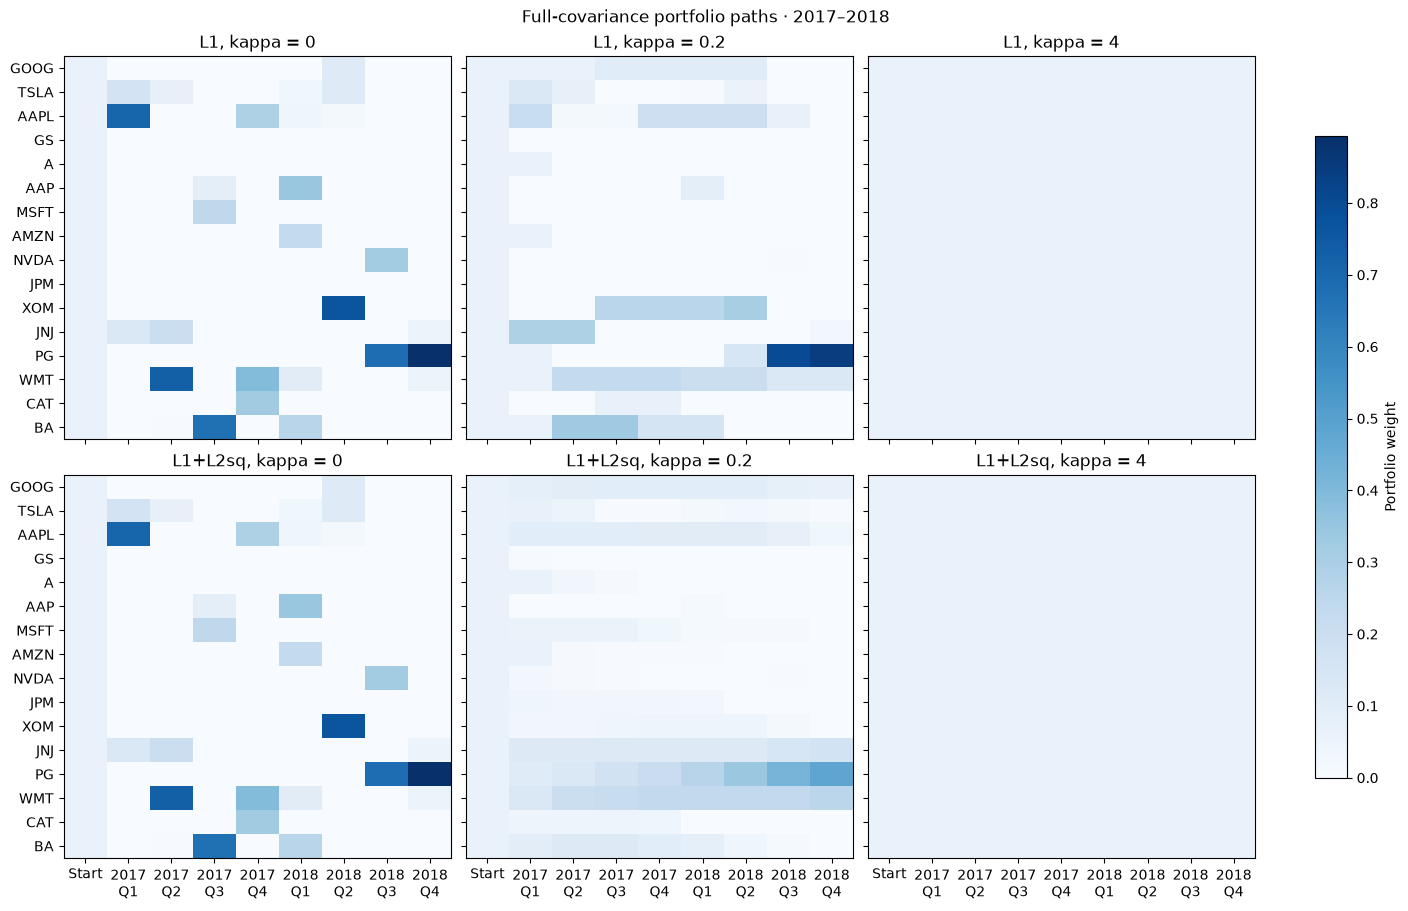

In [131]:
#show representative zero, intermediate, and high penalties
plot_kappas = [0.0, 0.2, 4.0]
#label the initial allocation and quarterly decisions
labels = ['Start'] + [period.replace('Q', '\nQ') for period in periods]
color_max = max(full_solutions[(m, k)].max() for m in cost_models for k in plot_kappas)
#create a row per model and a column per representative coefficient
fig, axes = plt.subplots(2, 3, figsize=(14, 9), sharex=True, sharey=True, layout='constrained')
#draw the paths for each transaction model
for i, cost_model in enumerate(cost_models):
    #draw each representative coefficient in its own panel
    for j, kappa in enumerate(plot_kappas):
        #include the starting portfolio before the eight optimized rows
        path = np.vstack([x0, full_solutions[(cost_model, kappa)]])
        #display assets as rows and decision periods as columns
        heatmap = axes[i, j].imshow(path.T, aspect='auto', cmap='Blues', vmin=0, vmax=color_max)
        #identify the model and coefficient
        axes[i, j].set_title(f'{cost_model}, kappa = {kappa:g}')
        #label all 16 assets in order
        axes[i, j].set_yticks(range(n), asset_lst)
        #label the initial portfolio and all quarterly decisions
        axes[i, j].set_xticks(range(H + 1), labels)
#label the shared color scale in portfolio weight units
fig.colorbar(heatmap, ax=axes, label='Portfolio weight', shrink=0.8)
fig.suptitle('Full-covariance portfolio paths · 2017–2018')
plt.show()

## 5. Discussion

- **No transaction penalty:** at $\kappa=0$, both models give the same solution, with turnover **13.486835** and objective **−1.954267**. The paths change substantially between quarters because trading is unpenalized.
- **Effect of increasing $\kappa$:** trading falls under both models in this sample. At $\kappa=4$, both paths stay at the equal-weight starting portfolio within numerical tolerance, with essentially zero turnover and penalty and objective **1.885590**. Within either model, the optimized objective cannot decrease as $\kappa$ rises because every feasible path receives a weakly larger nonnegative penalty. The paid penalty itself need not increase monotonically.
- **Effect of the quadratic term:** at $\kappa=0.2$, adding squared-trade costs reduces turnover from **4.957703 to 1.785067**, squared trades from **1.112533 to 0.070884**, and the largest trade from **65.55 to 8.18 percentage points**. The path adjusts more gradually. Total penalties are **0.991541** versus **0.640551**, and objectives are **−0.205018** versus **0.521629**. The objective definitions differ between models, so these values do not establish that one portfolio is universally better.

The penalties are model costs rather than calibrated brokerage fees. These known-input objective values do not measure realized profit or out-of-sample performance.

## Task 4(b): Dynamic PCA factor model

For each quarter, construct

$$
Q_{t,\mathrm{PCA},K}
=W_{t,K}\Lambda_{t,K}W_{t,K}^\top+D_{t,K},
\qquad
y_t=W_{t,K}^\top x_t,
$$

using the same procedure as Task 2(b).

For either transaction-cost model, solve

$$
\min_{\{x_t,y_t\}_{t=1}^H}
\sum_{t=1}^H
\left[
\lambda(y_t^\top\Lambda_{t,K}y_t+x_t^\top D_{t,K}x_t)
-\mu_t^\top x_t+C_\kappa(x_t-x_{t-1})
\right]
$$

subject to

$$
x_t\ge0,\qquad \mathbf1^\top x_t=1,\qquad y_t=W_{t,K}^\top x_t.
$$

### Requirements

1. Implement for the three values of $K$ in $\{2,5,8\}$. For each, run both cost models and the prescribed $\kappa$ values.
2. Compare paths, turnover, largest individual trade, and runtime with Task 4(a).
3. For each PCA-generated path, evaluate the **full-covariance dynamic objective with the same cost model**, and compare it with the full-covariance optimum. Report the objective gap and the path distance $\sum_t\|x_t^{\mathrm{PCA}}-x_t^{\mathrm{full}}\|_1$.
4. Verify agreement when $K=16$ for at least one positive $\kappa$ under each cost model.
5. Discuss how $K$ affects covariance approximation and portfolio decisions.


In [132]:
# Task 4(b): your dynamic PCA factor-model implementation
def solve_full_horizon_PCA(K, mu_path, W_path, lam_path, D_path, x0, kappa, cost_model):
    H, n = mu_path.shape
    X = cp.Variable((H, n))
    Y = cp.Variable((H, K))
    objective = 0
    constraints = [X >= 0, cp.sum(X, axis=1) == 1]
    for t in range(H):
        z = X[t] - (x0 if t == 0 else X[t - 1])
        cost = kappa * cp.norm1(z)
        if cost_model == 'L1+L2sq':
            cost += (kappa / q) * cp.sum_squares(z)
        objective += LAM * (cp.quad_form(Y[t], cp.psd_wrap(lam_path[t])) + cp.quad_form(X[t], cp.psd_wrap(D_path[t])))- mu_path[t] @ X[t] + cost
        constraints.append(Y[t] == W_path[t].T @ X[t])
    problem = cp.Problem(cp.Minimize(objective), constraints)
    problem.solve(solver=cp.OSQP, eps_abs=1e-9, eps_rel=1e-9, max_iter=200000,warm_start=False)
    assert problem.status == cp.OPTIMAL
    return X.value.copy(), float(problem.value)

In [133]:
eig_t = [PCA(Q_t)[1:3] for Q_t in Q_path]
K_grid = [2, 5, 8, 16]                  
pca_inputs = {}  
for K in K_grid:
    parts = [construct_Q_PCA(K, Q_t, L_t, W_t) for Q_t, (L_t, W_t) in zip(Q_path, eig_t)]
    pca_inputs[K] = tuple(np.array([d[key] for d in parts]) for key in ('W_K', 'lam_K', 'D_K', 'rel_cov_err'))
    W_path, lam_path, D_path, rel_err = pca_inputs[K]
    print(f'K={K:2d}: W_path {W_path.shape}, lam_path {lam_path.shape}, D_path {D_path.shape}, '
          f'rel. cov. error per quarter: mean {rel_err.mean():.3f}, max {rel_err.max():.3f}')


K= 2: W_path (8, 16, 2), lam_path (8, 2, 2), D_path (8, 16, 16), rel. cov. error per quarter: mean 0.199, max 0.276
K= 5: W_path (8, 16, 5), lam_path (8, 5, 5), D_path (8, 16, 16), rel. cov. error per quarter: mean 0.082, max 0.119
K= 8: W_path (8, 16, 8), lam_path (8, 8, 8), D_path (8, 16, 16), rel. cov. error per quarter: mean 0.048, max 0.075
K=16: W_path (8, 16, 16), lam_path (8, 16, 16), D_path (8, 16, 16), rel. cov. error per quarter: mean 0.000, max 0.000
